<b><font size="6" color="#E8800A">Homework · Group 44 · Part 1 — Import and explore the data</font></b><br>
<b><font size="4">Everything & Then Some, Ltd. · Predicting a repeat purchase within 90 days</font></b><br>

**Machine Learning 2026/2027 · NOVA IMS** · Kaggle team `ML_Group_44`

This notebook covers point 1 of the brief: *inspect `train.csv` and, if useful, `clientes.csv`; describe the
observations and variables; provide descriptive statistics; check data quality and inconsistencies; and explore
univariate and multivariate relationships.*

**Nothing in this notebook changes the data that the model will see.** Here we only *diagnose*. Every problem we
find is recorded with a planned fix, and the fixes are applied in Part 2 inside a reproducible pipeline that is fitted on
training rows only.

<div class="alert alert-block alert-warning">

**`test.csv` is not used in this notebook.** Point 1 of the brief asks to explore `train.csv` and `clientes.csv`, and
every conclusion here is drawn from those two files only. The test file is opened for the first time when the fitted
pipeline is applied to it to produce the submission. This keeps any information from the test set out of our
exploration choices, and therefore out of the model.

</div>

<div class="alert alert-block alert-info">

# TOC<a class="anchor" id="toc"></a>
* [<font color='#E8800A'>1 · The business need</font>](#business)
* [<font color='#E8800A'>2 · Setup</font>](#setup)
* [<font color='#E8800A'>3 · Import the data</font>](#import)
* [<font color='#E8800A'>4 · Structural survey: what is each column?</font>](#survey)
* [<font color='#E8800A'>5 · The target and the floor</font>](#target)
* [<font color='#E8800A'>6 · Data quality</font>](#quality)
* [<font color='#E8800A'>7 · Time structure: predicting the future</font>](#drift)
* [<font color='#E8800A'>8 · Univariate analysis</font>](#univariate)
* [<font color='#E8800A'>9 · Relationships with the target</font>](#bivariate)
* [<font color='#E8800A'>10 · Redundancy between predictors</font>](#redundancy)
* [<font color='#E8800A'>11 · The customer table `clientes.csv`</font>](#clientes)
* [<font color='#E8800A'>12 · Identifiers and the noise column</font>](#identifiers)
* [<font color='#E8800A'>13 · Key findings and decisions carried to Part 2</font>](#findings)

</div>

# <font color='#E8800A'>1 · The business need</font> <a class="anchor" id="business"></a>
[Back to TOC](#toc)

Everything & Then Some supplies businesses and specialist retailers (tools, lighting, automotive care, household
goods). The company wants to know **which customers are likely to come back soon after a purchase**, so it can plan
targeted commercial actions.

Following the five objects of a supervised problem (Week 1):

| Object | In this problem |
|---|---|
| **Observation** | one *purchase occasion* (one row of `train.csv`) |
| **Target** | `repeat_purchase_90d`: 1 if the same customer buys again within the next 90 days, 0 otherwise |
| **Features** | what is known **at the moment of that purchase**: the invoice itself, the customer's purchase history before it, the commercial context, and (optionally) the customer's master data |
| **Prediction moment** | right after the purchase is recorded. Nothing that happens after it may be used |
| **Decision** | whether to include the customer in a commercial action (e.g. a follow-up offer) |

The prediction moment matters for leakage: every history column in the file is named `prior_*` or describes a window
that *ends* at the purchase (`spend_30d`, `purchase_count_90d`, ...), so they are legitimate. We check this assumption
in Section 6.

**How the work is graded on Kaggle:** the competition metric is the **F1-score of class 1** computed on hard 0/1
predictions. This shapes the whole analysis, starting with the floor in Section 5.

# <font color='#E8800A'>2 · Setup</font> <a class="anchor" id="setup"></a>
[Back to TOC](#toc)

The usual stack: `pandas`/`numpy` for data, `matplotlib`/`seaborn` for plots, `joblib` to save fitted objects later,
and `scipy.stats` for the association measures used in class (point-biserial correlation, chi-square and Cramér's V).

The paths are built with `os.path.join`, so the notebook runs on Windows, macOS and Linux alike. We also name the three
columns with a **special structural role** once, here, and refer to them by these names everywhere:

* `target_col`: what we predict;
* `group_col`: the customer key. It links purchases of the same customer and joins `clientes.csv`; it is not a feature;
* `index_col`: the row identifier. It becomes the index and is kept unchanged for the submission file.

In [2]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import joblib
import seaborn as sns

# Extra tools used in this notebook (statistical tests seen in class)
import warnings
from scipy import stats
from scipy.stats import chi2_contingency

train_path=os.path.join("..","data","raw","train.csv")
clientes_path=os.path.join("..","data","raw","clientes.csv")

#Variables with special structural roles
target_col = "repeat_purchase_90d"
group_col = "customer_id"
index_col = "ID"

# Notebook settings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

RANDOM_STATE = 44                                  # our group number, used as seed everywhere
PLOT_BLUE, PLOT_ORANGE = "#1779A8", "#C96A00"      # course plot colours
FIGSIZE = (10, 4.5)

# <font color='#E8800A'>3 · Import the data</font> <a class="anchor" id="import"></a>
[Back to TOC](#toc)

Two files: `train.csv` (the purchase occasions with their outcome) and `clientes.csv` (the optional customer table).
`ID` identifies a row (a purchase occasion), so it goes straight into the index: that way it can never be
handed to a model by accident, and it stays untouched for the submission file.

> **Note:** we pass `index_col=index_col` (i.e. `"ID"`) and not `index_col=0`. The first column of `train.csv` is
> `Total a Pagar`, so `index_col=0` would silently turn the amount paid into the index and remove it from the
> features, while `ID` would stay as an ordinary column.

In [3]:
df_raw = pd.read_csv(train_path, index_col=index_col, sep=",")
df_clientes = pd.read_csv(clientes_path, sep=",")

for name, frame in [("train", df_raw), ("clientes", df_clientes)]:
    print(f"{name:9s} {frame.shape[0]:>6,} rows x {frame.shape[1]:>2} columns")

train      6,534 rows x 38 columns
clientes   1,143 rows x 13 columns


In [4]:
df_raw.head()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,1,79.0,126.0,2.0,858.30,429.150000,112.656252,349.49,508.81,47.000000,NaN,0.0,0.00,1.0,349.49,2.0,858.30,2.0,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,1,244.0,616.0,5.0,6722.83,1344.566000,1683.795178,84.38,4222.15,93.000000,117.657696,0.0,0.00,0.0,0.00,0.0,0.00,4.0,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510
10000002,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,1,9.0,610.0,90.0,17590.08,195.445333,190.389932,4.54,1002.15,6.752809,6.384073,2.0,111.27,9.0,1928.55,28.0,5290.25,49.0,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730
10000003,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,0,97.0,97.0,1.0,270.33,270.330000,NaN,270.33,270.33,NaN,NaN,0.0,0.00,0.0,0.00,1.0,270.33,1.0,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402
10000004,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,1,85.0,1575.0,25.0,12803.02,512.120800,406.696963,22.58,1736.74,62.083333,66.246520,0.0,0.00,2.0,184.13,4.0,2062.50,4.0,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890


In [5]:
# info() shows how each column was read and how many values are present.
df_raw.info()

<class 'pandas.DataFrame'>
Index: 6534 entries, 10000000 to 10007674
Data columns (total 38 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 no

**First observations**

* `train.csv` has **6,534 purchase occasions** and 38 columns besides the index (37 features and the target).
* All the money and count columns were read as numbers, the 7 text columns as strings, and `purchase_date` as text
  (it will need to be parsed).
* Many columns have exactly **6,469 non-null values** → the same 65 rows seem to be empty in all of them (Section 6.1).
* Several history columns (`prior_*`, `days_since_previous_purchase`) have far fewer values → structural missingness (Section 6.3).

# <font color='#E8800A'>4 · Structural survey: what is each column?</font> <a class="anchor" id="survey"></a>
[Back to TOC](#toc)

To better organize our data we chose to group the variables by themes. Every later section refers to these groups,
which makes the material easier to find, and the rest of the notebook treats each group consistently: nothing is
treated that was not named here.

In [6]:
#Variables with special structural roles are defined in the setup: target_col, group_col, index_col

# Grouping by themes
var_groups = {
    "Identifier": [
        "ID",
        "customer_id"
    ],
    "Target": [
        "repeat_purchase_90d"
    ],
    "Current transaction (financial)": [
        "Total a Pagar",
        "Total Bruto",
        "Total Liquido",
        "Total Imp_",
        "Total Portes",
        "Total Desc_ Global",
        "Total Desc_ Linha",
        "Custo"
    ],
    "Current transaction (operational)": [
        "N_ Detalhes",
        "invoice_count_current_purchase"
    ],
    "Transaction context & date": [
        "purchase_date",
        "payment_type",
        "salesperson",
        "commercial_zone",
        "warehouse",
        "document_series",
        "transport_method"
    ],
    "Customer historical summary": [
        "customer_tenure_days",
        "prior_purchase_count",
        "prior_total_spend",
        "prior_mean_purchase_value",
        "prior_std_purchase_value",
        "prior_min_purchase_value",
        "prior_max_purchase_value"
    ],
    "Customer cadence & gaps": [
        "days_since_previous_purchase",
        "prior_mean_gap_days",
        "prior_std_gap_days"
    ],
    "Rolling windows (RFM)": [
        "purchase_count_30d",
        "spend_30d",
        "purchase_count_90d",
        "spend_90d",
        "purchase_count_180d",
        "spend_180d",
        "purchase_count_365d",
        "spend_365d"
    ],
    "Synthetic / Control": [
        "random_noise"
    ]
}

# Sanity check: every column of the file (index included) is in exactly one group
listed = [c for cols in var_groups.values() for c in cols]
assert sorted(listed) == sorted([index_col] + list(df_raw.columns)), "a column is missing from var_groups"

# Column lists used in the rest of the notebook, built from the groups
date_col = "purchase_date"
numeric_cols = (var_groups["Current transaction (financial)"] + var_groups["Current transaction (operational)"]
                + var_groups["Customer historical summary"] + var_groups["Customer cadence & gaps"]
                + var_groups["Rolling windows (RFM)"])
categorical_cols = [c for c in var_groups["Transaction context & date"] if c != date_col]

pd.DataFrame(
    [(group, len(cols), ", ".join(cols)) for group, cols in var_groups.items()], columns=["Group", "# vars", "Variables"])

,Group,# vars,Variables
0,Identifier,2,"ID, customer_id"
1,Target,1,repeat_purchase_90d
2,Current transaction (financial),8,"Total a Pagar, Total Bruto, Total Liquido, Tot..."
3,Current transaction (operational),2,"N_ Detalhes, invoice_count_current_purchase"
4,Transaction context & date,7,"purchase_date, payment_type, salesperson, comm..."
5,Customer historical summary,7,"customer_tenure_days, prior_purchase_count, pr..."
6,Customer cadence & gaps,3,"days_since_previous_purchase, prior_mean_gap_d..."
7,Rolling windows (RFM),8,"purchase_count_30d, spend_30d, purchase_count_..."
8,Synthetic / Control,1,random_noise


* **Identifier** and **Target** hold the three structural roles defined in the setup.
* The current transaction is split in two: the **financial** amounts of the invoice and its **operational** size
  (number of lines and of invoices).
* The customer's past is split by what it measures: **historical summary** (how long, how many, how much),
  **cadence & gaps** (how often and how recently) and **rolling windows** (recent frequency and monetary value, the
  F and M of RFM).
* `random_noise` gets its own **Synthetic / Control** group: we do not trust it, but we keep it as a control (Section 12).

The column lists used in the rest of the notebook (`numeric_cols`, `categorical_cols`) are built from these groups, so
there is a single source of truth.

We then apply the identifier rule from Week 3: *a column that is distinct on more than half of its rows identifies
the row rather than describing it.*

In [7]:
# Columns that are (almost) unique per row behave like identifiers, whatever their dtype.
distinct_share = (df_raw.reset_index().nunique() / len(df_raw)).sort_values(ascending=False)
distinct_share.head(6).round(3).to_frame("share of distinct values")

,share of distinct values
ID,1.000
random_noise,0.990
Total a Pagar,0.937
Total Liquido,0.933
Total Bruto,0.924
prior_total_spend,0.897


`ID` is unique per row, as expected. `random_noise` is also almost unique per row, but it is a continuous
number, so the rule alone does not settle it. Its name is suspicious and we test it in Section 12.
`customer_id` is **not** unique: 610 customers for 6,534 purchases (Section 6.2).

In [8]:
# A dtype is how a value is stored, not what it measures: numeric columns with few distinct
# values could be codes written as numbers.
low_card = {c: df_raw[c].nunique() for c in numeric_cols if df_raw[c].nunique() <= 10}
print("numeric columns with <= 10 distinct values:", low_card)
print("\nlevels per categorical column:")
print(df_raw[categorical_cols].nunique().sort_values(ascending=False).to_string())

numeric columns with <= 10 distinct values: {'invoice_count_current_purchase': 5}

levels per categorical column:
transport_method    80
payment_type         9
salesperson          9
commercial_zone      5
document_series      3
warehouse            2


* The only low-cardinality numeric column is `invoice_count_current_purchase` (1 to 5 invoices in the same
  purchase occasion). It is a genuine count, not a code, so it stays numeric.
* The categoricals go from 2 levels (`warehouse`) to **80 levels** (`transport_method`). The labels are anonymised
  ("Maybe Tomorrow Payment 10", "VLOOKUP Master 9", ...), so they carry no domain meaning we could exploit by hand;
  their value can only be measured against the target (Section 9.3).

# <font color='#E8800A'>5 · The target and the floor</font> <a class="anchor" id="target"></a>
[Back to TOC](#toc)

Look at the target before looking at anything against it. **A score means nothing on its own**: it must be read
against what a model that does no work would get (Week 1).

In [9]:
balance = df_raw[target_col].value_counts().sort_index()
print(balance.to_frame("rows").assign(share=lambda f: (f["rows"] / f["rows"].sum()).round(3)).to_string())

# The two floors: always predict the majority class (accuracy), and always predict 1 (F1 of class 1).
p = df_raw[target_col].mean()
print(f"\nalways predict 1 -> accuracy {p:.3f} | F1(class 1) {2 * p / (1 + p):.3f}")
print(f"always predict 0 -> accuracy {1 - p:.3f} | F1(class 1) 0.000")

                     rows  share
repeat_purchase_90d             
0                    2880  0.441
1                    3654  0.559

always predict 1 -> accuracy 0.559 | F1(class 1) 0.717
always predict 0 -> accuracy 0.441 | F1(class 1) 0.000


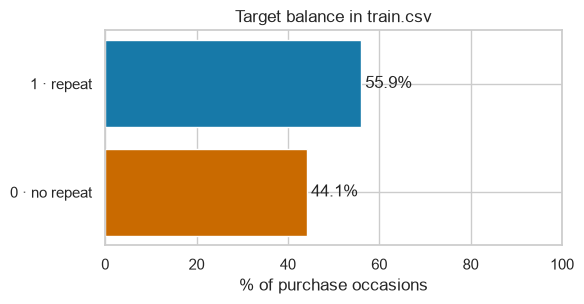

In [10]:
fig, ax = plt.subplots(figsize=(6, 3.2))
shares = df_raw[target_col].value_counts(normalize=True).sort_index() * 100
ax.barh(["0 · no repeat", "1 · repeat"], shares.values, color=[PLOT_ORANGE, PLOT_BLUE])
for i, v in enumerate(shares.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center")
ax.set(xlim=(0, 100), xlabel="% of purchase occasions", title="Target balance in train.csv")
plt.tight_layout()
plt.show()

**What this tells us**

* The classes are **mildly imbalanced, and class 1 is the majority** (≈56%). That is unusual: in most screening
  problems the positive class is rare.
* Because the competition scores the **F1 of class 1**, the trivial model "everybody comes back" already scores
  **F1 ≈ 0.72**. F1 ignores true negatives, so predicting 1 is cheap and missing a 1 is expensive.
* Two consequences for later: (1) every F1 we report will be compared with the all-ones floor, and
  (2) the decision **threshold** is part of the model. The default 0.5 is not necessarily the one that maximises F1.
* Resampling (SMOTE, undersampling) is not needed: the minority class still has ≈2,900 rows.

# <font color='#E8800A'>6 · Data quality</font> <a class="anchor" id="quality"></a>
[Back to TOC](#toc)

We first **diagnose** and only later fix, so we know exactly what each fix does and how many rows it touches.

### 6.1 Rows with no information

In [11]:
# How many values does each row carry, ignoring the identifiers and the target?
info_cols = [c for c in df_raw.columns if c not in [group_col, target_col]]
filled = df_raw[info_cols].notna().sum(axis=1)
print(filled.value_counts().sort_index().tail(8).to_string())

empty_rows = filled == 0
print(f"\nrows with ZERO informative values: {empty_rows.sum()} "
      f"({100 * empty_rows.mean():.2f}% of df_raw), repeat rate {df_raw.loc[empty_rows, target_col].mean():.2f}")

28      86
29     511
31       6
32     100
33     354
34     190
35    1287
36    3929

rows with ZERO informative values: 65 (0.99% of df_raw), repeat rate 0.51


**65 rows (1%) carry nothing but `customer_id` and the target.** No invoice, no history, no date, no category. They
look like failed extractions. (They are also the reason a naive `duplicated()` on the raw file reports 10 duplicate rows:
empty rows of the same customer look identical.) No imputation can recover a row that has no measured value: every feature would be an invented
number, and the model would learn from rows that describe no real purchase.
→ **Planned fix:** drop these 65 training rows.

### 6.2 Duplicates and repeated customers

Three questions (Week 3): exact copies, repeated identifiers, and repeated entities.

In [12]:
# df = the working copy of train without the 65 empty rows (df_raw stays untouched for comparison)
df = df_raw.loc[~empty_rows]

print("exact duplicate rows (ignoring ID):", df.duplicated().sum())
print("duplicate rows ignoring ID AND target:", df.drop(columns=target_col).duplicated().sum())
print("duplicated IDs:", df_raw.index.duplicated().sum())

per_customer = df_raw.groupby(group_col).size()
print(f"\n{df_raw['customer_id'].nunique()} customers for {len(df_raw):,} purchases")
print(per_customer.describe().round(1).to_string())

exact duplicate rows (ignoring ID): 0
duplicate rows ignoring ID AND target: 0
duplicated IDs: 0

610 customers for 6,534 purchases
count    610.0
mean      10.7
std       20.0
min        1.0
25%        1.0
50%        4.0
75%       12.0
max      277.0


In [13]:
# On the RAW file, duplicated() finds copies; are they all among the empty rows?
raw_dups = df_raw.duplicated(keep=False)
print("rows involved in a duplicate on the raw file:", raw_dups.sum(),
      "| of which empty rows:", (raw_dups & empty_rows).sum())

rows involved in a duplicate on the raw file: 16 | of which empty rows: 16


* Once the empty rows are set aside there are **no duplicated purchases**: every informative row is distinct. The
  duplicates a quick check reports on the raw file are all empty rows of the same customer, already handled by 6.1.
* The more important fact is that **customers repeat**: 610 customers, median 4 purchases each, and one customer with
  **277**. Rows of the same customer are not independent, so a random split puts purchases of the same customer on
  both sides. Section 7 shows why this matters for validation.

### 6.3 Missing values

From here on we look at the rows that carry information (the 65 empty rows would otherwise dominate every count).

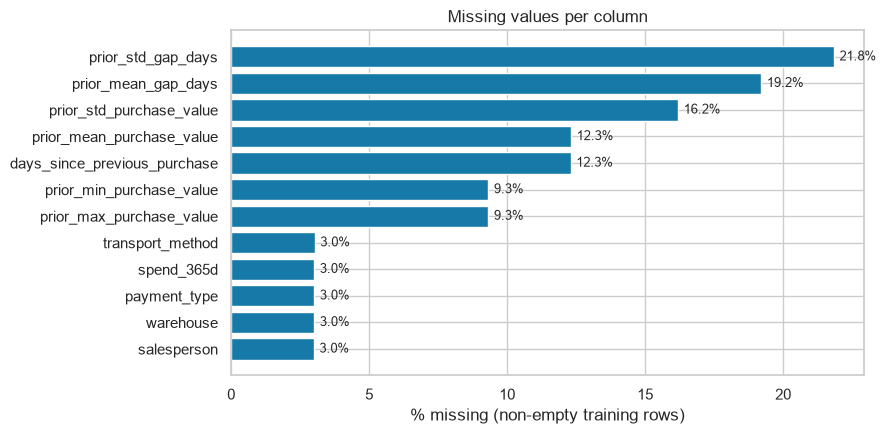

,n_missing,pct
prior_std_gap_days,1413,21.84
prior_mean_gap_days,1243,19.21
prior_std_purchase_value,1048,16.20
prior_mean_purchase_value,797,12.32
days_since_previous_purchase,796,12.30
prior_min_purchase_value,603,9.32
prior_max_purchase_value,603,9.32
transport_method,196,3.03
spend_365d,195,3.01
payment_type,195,3.01


In [14]:
missing = (df.isna().sum().to_frame("n_missing")
           .assign(pct=lambda f: 100 * f["n_missing"] / len(df))
           .query("n_missing > 0").sort_values("n_missing", ascending=False))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(missing.index, missing["pct"], color=PLOT_BLUE)
for i, v in enumerate(missing["pct"]):
    ax.text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=9)
ax.invert_yaxis()
ax.set(xlabel="% missing (non-empty training rows)", title="Missing values per column")
plt.tight_layout()
plt.show()
missing.round(2)

Two different patterns appear:

1. **History columns** (`prior_*_gap_days`, `prior_std_purchase_value`, `days_since_previous_purchase`, ...): 12–22% missing.
   These could be *structural*: a customer with no previous purchase has no gap and no "days since previous purchase".
2. **Commercial context** (`payment_type`, `salesperson`, `transport_method`, `warehouse`) and `spend_365d`: ≈3% each.

We test both hypotheses instead of assuming them.

> These are the missing values **as the file delivers them**. Section 6.4 shows that part of them can be recovered
> exactly (194 values of `prior_mean_purchase_value`), and that some present values are wrong and become unknown.
> The diagnosis here stays on the raw file on purpose: it describes the data we received.

In [15]:
# Hypothesis 1: history columns are missing because the customer has (almost) no history.
history_missing = ["days_since_previous_purchase", "prior_mean_purchase_value", "prior_std_purchase_value",
                   "prior_min_purchase_value", "prior_mean_gap_days", "prior_std_gap_days"]
prior_n = df["prior_purchase_count"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
table = (df[history_missing].isna()
         .groupby(prior_n).mean().mul(100).round(1)
         .assign(rows=prior_n.value_counts()))
table.index.name = "prior purchases"
table

,days_since_previous_purchase,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_mean_gap_days,prior_std_gap_days,rows
prior purchases,,,,,,,
0,100.0,100.0,100.0,100.0,100.0,100.0,603
1,4.3,4.5,100.0,0.0,100.0,100.0,445
2,5.5,3.0,0.0,0.0,5.8,100.0,365
3+,3.0,3.2,0.0,0.0,3.4,0.0,5056


The hypothesis holds **only in part**:

* With **0 prior purchases**, every history column is missing in 100% of rows, as expected: there is no history.
* With **1 prior purchase**, the gap and the standard deviations are always missing (one purchase has no gap and no
  spread), but `days_since_previous_purchase` should exist, and it is still missing for a fraction of rows.
* With **2 or more** prior purchases, all these columns *should* exist, yet a few percent are missing anyway. That
  part is ordinary missingness, not structural.

So "missing = no history" (the business-logic reading, MNAR) explains most but not all of it. This decides the fix: we
add an explicit flag such as `is_first_purchase` (`prior_purchase_count == 0`) and *missing indicators*, then impute
the remaining gaps with the **training median**. We do **not** fill gaps with 0: a gap of 0 days would mean "buys every
day", which is the opposite of "no history".

In [16]:
# Hypothesis 2: are the context gaps random? Check overlap between columns and the target rate.
context_missing = ["payment_type", "salesperson", "transport_method", "warehouse", "spend_365d"]
flags = df[context_missing].isna()
print("rows missing in k of these 5 columns:", flags.sum(axis=1).value_counts().sort_index().to_dict())

rates = pd.DataFrame({
    "rows missing": flags.sum(),
    "repeat rate when missing": [df.loc[flags[c], target_col].mean() for c in context_missing],
    "repeat rate when present": [df.loc[~flags[c], target_col].mean() for c in context_missing],
}).round(3)
rates

rows missing in k of these 5 columns: {0: 5544, 1: 875, 2: 50}


,rows missing,repeat rate when missing,repeat rate when present
payment_type,195,0.564,0.560
salesperson,194,0.598,0.559
transport_method,196,0.551,0.560
warehouse,195,0.636,0.557
spend_365d,195,0.564,0.560


In [17]:
# Is missingness associated with any categorical feature? (chi-square + Cramer's V, Week 3)
def cramers_v(x, y):
    """Chi-square test on a contingency table and Cramer's V as effect size (0 = none, 1 = perfect)."""
    table = pd.crosstab(x, y)
    if min(table.shape) < 2:
        return np.nan, np.nan
    chi2, p_value, _, _ = chi2_contingency(table, correction=False)
    v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
    return v, p_value


rows = []
for flag_col in context_missing:
    for col in [c for c in categorical_cols if c != flag_col]:
        v, p_value = cramers_v(flags[flag_col], df[col].fillna("<missing>"))
        rows.append({"missing in": flag_col, "vs": col, "Cramer's V": v, "p": p_value})
assoc = pd.DataFrame(rows).pivot(index="missing in", columns="vs", values="Cramer's V").round(3)
assoc

vs,commercial_zone,document_series,payment_type,salesperson,transport_method,warehouse
missing in,,,,,,
payment_type,0.071,0.012,NaN,0.035,0.083,0.008
salesperson,0.005,0.026,0.026,NaN,0.101,0.012
spend_365d,0.005,0.015,0.039,0.023,0.104,0.010
transport_method,0.010,0.025,0.035,0.021,NaN,0.006
warehouse,0.005,0.021,0.051,0.024,0.140,NaN


* The context gaps **almost never overlap** (no row misses more than two of these columns), and the repeat rate is
  practically the same with and without the value. The one visible gap (`warehouse`: 0.64 vs 0.56) rests on 195 rows,
  about two standard errors, so it is weak evidence.
* Missingness has at most a **weak** association with the other categoricals (Cramér's V ≤ 0.14). The largest values
  all involve `transport_method`, whose 80 levels inflate V on their own.
* Overall this is consistent with values **missing (close to) completely at random (MCAR)**.
* → **Planned fix:** categorical gaps become their own level `"Missing"` (cheap, and honest about the gap);
  `spend_365d` gaps are imputed with the training median (after the cleaning in 6.4).

### 6.4 Impossible values

`describe()` is the quickest way to spot values that the domain forbids.

In [18]:
df[numeric_cols].describe().T[["min", "25%", "50%", "75%", "max"]].round(2)

,min,25%,50%,75%,max
Total a Pagar,0.93,188.92,476.74,1087.67,2.229721e+04
Total Bruto,0.83,175.74,445.74,1036.70,2.157828e+04
Total Liquido,0.76,154.38,389.91,903.37,1.812781e+04
Total Imp_,0.00,29.93,79.74,184.84,4.169400e+03
Total Portes,0.00,0.00,0.00,0.00,1.810600e+02
Total Desc_ Global,0.00,0.00,0.00,0.00,2.184900e+02
Total Desc_ Linha,0.00,0.00,13.13,92.28,4.103440e+03
Custo,0.00,49.05,152.54,396.06,7.427400e+03
N_ Detalhes,1.00,4.00,11.00,29.00,4.230000e+02
invoice_count_current_purchase,1.00,1.00,1.00,1.00,5.000000e+00


Three things cannot be true:

* `prior_mean_purchase_value` and `spend_365d` reach **1,000,000,000** (one billion euros), while their medians are
  ≈725 € and ≈2,400 €.
* `days_since_previous_purchase` and `prior_mean_gap_days` have **negative** values (a gap cannot be negative), and
  `prior_mean_purchase_value` and `spend_365d` too (spending cannot be negative).

Random damage would scatter over many values. Placeholders sit on a few exact values, so we look at the values themselves.

In [19]:
checks = {
    "prior_mean_purchase_value": df["prior_mean_purchase_value"],
    "spend_365d": df["spend_365d"],
    "days_since_previous_purchase": df["days_since_previous_purchase"],
    "prior_mean_gap_days": df["prior_mean_gap_days"],
}
for name, s in checks.items():
    bad = s[(s < 0) | (s >= 1e8)]
    print(f"{name:30s} {len(bad):3d} impossible values -> {bad.value_counts().head(4).to_dict()}")

prior_mean_purchase_value       32 impossible values -> {1000000000.0: 16, -110.14709677419351: 1, -409.7916666666667: 1, -218.2663917525773: 1}
spend_365d                      30 impossible values -> {1000000000.0: 15, -3456.32: 1, -1230.72: 1, -167.18: 1}
days_since_previous_purchase    16 impossible values -> {-4.0: 16}
prior_mean_gap_days             16 impossible values -> {-4.0: 16}


In [20]:
# Do the two kinds of impossible values sit on the same rows?
def sentinel_mask(frame):
    return pd.DataFrame({
        "billion": (frame["prior_mean_purchase_value"] >= 1e8) | (frame["spend_365d"] >= 1e8),
        "negative": (frame["days_since_previous_purchase"] < 0) | (frame["prior_mean_gap_days"] < 0)
                    | (frame["prior_mean_purchase_value"] < 0) | (frame["spend_365d"] < 0),
    })


s_train = sentinel_mask(df)
print(pd.crosstab(s_train["billion"], s_train["negative"]).rename_axis(index="billion", columns="negative"))
print(f"\nrows with at least one impossible value: {s_train.any(axis=1).sum()}")
print("repeat rate on these rows:", round(df.loc[s_train.any(axis=1), target_col].mean(), 3))

negative  False  True 
billion               
False      6375     63
True         31      0

rows with at least one impossible value: 94
repeat rate on these rows: 0.532


* There are **two kinds of impossible values, on different rows**: the value **1e9** (31 rows, in
  `prior_mean_purchase_value` and `spend_365d`) and **negative values** (63 rows): exactly −4 days in the two gap
  columns, and negative amounts in the two money columns. In total 94 rows (1.5%) carry at least one impossible cell.
* 1e9 and −4 are exact repeated values, so they are codes written by the source system. The negative amounts are all
  different, so they need a closer look (6.4.1).
* The other columns of those rows look normal, and their repeat rate (0.53) is close to the average: only the cell is
  wrong, not the whole row. The fix should therefore act on the cell, not delete the row.

#### 6.4.1 Where do the negative money values come from?

A *mean* purchase value cannot be negative, so we checked how the column is built. By definition,
`prior_mean_purchase_value` should be the total spent before the purchase divided by the number of previous purchases:

$$\text{prior\_mean\_purchase\_value} = \frac{\text{prior\_total\_spend}}{\text{prior\_purchase\_count}}$$

We recompute this ratio for every row and compare it with the stored value, separately for normal, negative and
1e9 values.

In [21]:
recomputed_mean = df["prior_total_spend"] / df["prior_purchase_count"].replace(0, np.nan)
stored_mean = df["prior_mean_purchase_value"]

is_billion = stored_mean >= 1e8
is_negative = stored_mean < 0
is_normal = stored_mean.notna() & ~is_billion & ~is_negative

pd.DataFrame({
    "rows": [is_normal.sum(), is_negative.sum(), is_billion.sum()],
    "stored = total / count": [np.isclose(stored_mean[m], recomputed_mean[m]).mean()
                               for m in (is_normal, is_negative, is_billion)],
    "|stored| = total / count": [np.isclose(stored_mean[m].abs(), recomputed_mean[m]).mean()
                                 for m in (is_normal, is_negative, is_billion)],
    "total / count can be computed": [recomputed_mean[m].notna().mean()
                                      for m in (is_normal, is_negative, is_billion)],
}, index=["normal values", "negative values", "1e9 values"]).round(3)

,rows,stored = total / count,|stored| = total / count,total / count can be computed
normal values,5640,0.992,0.992,1.0
negative values,16,0.000,1.000,1.0
1e9 values,16,0.000,0.000,1.0


In [22]:
# A few of the negative rows side by side: the stored value is the ratio with the sign flipped.
pd.DataFrame({
    "prior_total_spend": df.loc[is_negative, "prior_total_spend"],
    "prior_purchase_count": df.loc[is_negative, "prior_purchase_count"],
    "total / count": recomputed_mean[is_negative],
    "stored prior_mean_purchase_value": stored_mean[is_negative],
}).head(5).round(2)

,prior_total_spend,prior_purchase_count,total / count,stored prior_mean_purchase_value
ID,,,,
10000018,3414.56,31.0,110.15,-110.15
10000519,2458.75,6.0,409.79,-409.79
10000536,42343.68,194.0,218.27,-218.27
10001157,2925.42,7.0,417.92,-417.92
10001375,3895.15,5.0,779.03,-779.03


* **The formula holds**: for 99.2% of the normal rows, the stored mean is exactly total / count.
* **The 16 negative values are a sign error**: in every one of them, the stored value is exactly
  `−(prior_total_spend / prior_purchase_count)`. There is no business logic behind a negative mean.
* **The 16 values of 1e9 can be recovered as well**: all these customers have previous purchases, so total / count can
  be computed for every one of them.

The 0.8% of "normal" rows where the formula does not hold deserve a look of their own.

In [23]:
# Normal-looking values that do NOT match total / count: how far off are they, and are they even possible?
mismatch = is_normal & ~np.isclose(stored_mean, recomputed_mean)
ratio = stored_mean[mismatch] / recomputed_mean[mismatch]
print(f"normal-looking rows that do not match the formula: {mismatch.sum()}")
print(f"stored / recomputed: min {ratio.min():.1f}x, median {ratio.median():.1f}x, max {ratio.max():.1f}x")
print(f"stored mean ABOVE the customer's largest prior purchase: "
      f"{(stored_mean[mismatch] > df.loc[mismatch, 'prior_max_purchase_value']).sum()} of {mismatch.sum()}")

inside_range = ((recomputed_mean >= df["prior_min_purchase_value"] - 0.01)
                & (recomputed_mean <= df["prior_max_purchase_value"] + 0.01))
print(f"recomputed mean inside [prior_min, prior_max] (all rows where both exist): "
      f"{inside_range[recomputed_mean.notna() & df['prior_max_purchase_value'].notna()].mean():.1%}")

normal-looking rows that do not match the formula: 46
stored / recomputed: min 8.5x, median 16.1x, max 24.8x
stored mean ABOVE the customer's largest prior purchase: 45 of 46
recomputed mean inside [prior_min, prior_max] (all rows where both exist): 100.0%


This is a **third, hidden error** that `describe()` cannot show, because the values look plausible on their own:
in 46 rows the stored mean is between ≈8 and ≈25 times the true ratio, and in 45 of them it is **larger than the
customer's largest previous purchase**, which is impossible for a mean. The recomputed ratio, on the other hand, always
falls between the customer's smallest and largest previous purchase, as a mean must.

**Conclusion for `prior_mean_purchase_value`:** the stored column is unreliable in 78 rows (16 negative, 16 × 1e9, 46
inflated), while total / count is always available and always consistent. The column is fully determined by two other
columns, so it can be **recomputed for every row**. This also means it is **redundant by construction**, which matters
for feature selection (Part 3).

#### 6.4.2 And the negative values of `spend_365d`?

`spend_365d` cannot be recomputed from other columns, but it must respect two bounds: it includes the last 180 days, so
it is at least `spend_180d`, and it is part of the whole history, so it is at most `prior_total_spend`. We check
whether the negative values fit these bounds once the sign is removed.

In [24]:
spend = df["spend_365d"]
spend_negative = spend < 0
spend_billion = spend >= 1e8
spend_normal = spend.notna() & ~spend_negative & ~spend_billion


def inside_bounds(values, rows):
    """True where a 365-day spend lies between the 180-day spend and the full prior spend (1 cent tolerance)."""
    return ((values >= df.loc[rows, "spend_180d"] - 0.01)
            & (values <= df.loc[rows, "prior_total_spend"] + 0.01))


pd.DataFrame({
    "rows": [spend_normal.sum(), spend_negative.sum()],
    "value inside the bounds": [inside_bounds(spend[spend_normal], spend_normal).mean(),
                                inside_bounds(spend[spend_negative], spend_negative).mean()],
    "|value| inside the bounds": [inside_bounds(spend[spend_normal].abs(), spend_normal).mean(),
                                  inside_bounds(spend[spend_negative].abs(), spend_negative).mean()],
}, index=["normal spend_365d", "negative spend_365d"]).round(3)

,rows,value inside the bounds,|value| inside the bounds
normal spend_365d,6244,0.994,0.994
negative spend_365d,15,0.000,0.933


In [25]:
# The negative value that does not fit the bounds even without its sign
outside = spend_negative & ~inside_bounds(spend.abs(), df.index)
df.loc[outside, ["spend_180d", "spend_365d", "prior_total_spend"]]

,spend_180d,spend_365d,prior_total_spend
ID,,,
10004848,5631.64,-159115.175535,49328.65


* **14 of the 15 negative values are a sign error too**: without the sign they fall exactly where a 365-day spend
  must be.
* **One negative value cannot be explained**: −159,115 € in absolute value is three times the customer's whole prior
  spend (49,329 €). No correction is defensible, so it is treated as unknown.
* The same bounds reveal a **hidden problem among the "normal" values**: 0.6% of them (39 rows) are *above* the
  customer's whole prior spend, which is impossible. We look at them below.
* The 15 values of **1e9** cannot be reconstructed from other columns.

In [26]:
# Positive spend_365d values ABOVE the customer's whole prior spend: how far above?
too_high = spend_normal & (spend > df["prior_total_spend"] + 0.01)
too_low = spend_normal & (spend < df["spend_180d"] - 0.01)
excess = spend[too_high] / df.loc[too_high, "prior_total_spend"]
print(f"spend_365d above prior_total_spend: {too_high.sum()} rows "
      f"(between {excess.min():.1f}x and {excess.max():.1f}x the whole prior spend, median {excess.median():.1f}x)")
print(f"spend_365d below spend_180d: {too_low.sum()} rows")

spend_365d above prior_total_spend: 39 rows (between 1.5x and 23.2x the whole prior spend, median 10.8x)
spend_365d below spend_180d: 0 rows


These 39 values look plausible on their own (`describe()` cannot flag them), but a customer cannot spend more in the
last year than in their whole history. They are inflated by a factor of 1.5 to 23, the same kind of corruption as the
46 inflated means of 6.4.1. Here there is no formula to recover the true value, so they are treated as unknown.

#### 6.4.3 Missing values that can be recovered

The formula of 6.4.1 also helps with *missing* values: `prior_mean_purchase_value` is empty in some rows where
`prior_total_spend` and `prior_purchase_count` are known.

In [27]:
recoverable = stored_mean.isna() & recomputed_mean.notna()
print(f"prior_mean_purchase_value missing: {stored_mean.isna().sum()} rows")
print(f"  of which recoverable as total / count: {recoverable.sum()}")
print(f"  truly unknown (no previous purchase): {(stored_mean.isna() & recomputed_mean.isna()).sum()}")

prior_mean_purchase_value missing: 797 rows
  of which recoverable as total / count: 194
  truly unknown (no previous purchase): 603


194 of the missing means are not unknown at all: they can be computed exactly. The only rows where the mean really
does not exist are the first purchases (no previous purchase, so no mean). Section 6.3 shows the missing values as the
file delivers them; after this rule, `prior_mean_purchase_value` is missing **only** for first purchases.

#### 6.4.4 Row-by-row corrections

| Column | Problem | Rows | Fix |
|---|---|---|---|
| `prior_mean_purchase_value` | negative (sign error), 1e9, inflated (mean > max), or missing although computable | 16 + 16 + 46 + 194 | **recompute** as `prior_total_spend / prior_purchase_count` for every row (empty only for first purchases) |
| `spend_365d` | negative, inside the bounds once the sign is removed | 14 | **`abs()`**, sign corrected |
| `spend_365d` | 1e9, or outside `[spend_180d, prior_total_spend]` (inflated values and the unexplained negative) | 15 + 39 + 1 | → `NaN`, then training-median imputation (Part 2) |
| `days_since_previous_purchase`, `prior_mean_gap_days` | exactly −4 (code) | 16 + 16 | → `NaN`, then training-median imputation (Part 2) |

All of these are **row-by-row rules**: each corrected value is computed from the same row, and nothing is learned from
other rows, so they can be applied before any split without leakage, and to any new data in exactly the same way.
Recovering the true value is better than imputing: an imputed median is an invented number, while total / count is the
real one.

We write the rules once, as a function. The rest of this notebook explores the corrected data (`df_eda`, created in
Section 8), and Part 2 will reuse exactly the same function inside the pipeline.

In [28]:
def apply_row_corrections(frame):
    """Fix impossible values row by row (Section 6.4). Learns nothing from other rows, so it is leakage-free."""
    out = frame.copy()

    # 1. The mean purchase value is total / count by definition: recompute it for every row.
    out["prior_mean_purchase_value"] = out["prior_total_spend"] / out["prior_purchase_count"].replace(0, np.nan)

    # 2. spend_365d: 1e9 is a code; a negative value inside the bounds is a sign error.
    spend = out["spend_365d"].mask(out["spend_365d"] >= 1e8)
    spend = spend.abs()
    # A 365-day spend must lie between the 180-day spend and the whole prior spend; otherwise it is unknown.
    inside = (spend >= out["spend_180d"] - 0.01) & (spend <= out["prior_total_spend"] + 0.01)
    out["spend_365d"] = spend.where(inside)

    # 3. A gap of exactly -4 days is a code, not a measurement.
    for col in ["days_since_previous_purchase", "prior_mean_gap_days"]:
        out[col] = out[col].mask(out[col] < 0)
    return out


corrected = apply_row_corrections(df)
changes = pd.DataFrame({
    "values changed": [(~np.isclose(corrected[c].fillna(-1), df[c].fillna(-1))).sum() for c in
                       ["prior_mean_purchase_value", "spend_365d", "days_since_previous_purchase", "prior_mean_gap_days"]],
    "missing before": [df[c].isna().sum() for c in
                       ["prior_mean_purchase_value", "spend_365d", "days_since_previous_purchase", "prior_mean_gap_days"]],
    "missing after": [corrected[c].isna().sum() for c in
                      ["prior_mean_purchase_value", "spend_365d", "days_since_previous_purchase", "prior_mean_gap_days"]],
}, index=["prior_mean_purchase_value", "spend_365d", "days_since_previous_purchase", "prior_mean_gap_days"])
changes

,values changed,missing before,missing after
prior_mean_purchase_value,272,797,603
spend_365d,69,195,250
days_since_previous_purchase,16,796,812
prior_mean_gap_days,16,1243,1259


### 6.5 Internal consistency

Several columns are linked by definition. If the links hold, we can trust the columns (and we learn that some of
them are **redundant by construction**).

In [29]:
def share_true(condition):
    return f"{100 * condition.mean():.1f}%"

d = df
consistency = {
    "Bruto - Desc_Linha - Desc_Global = Liquido": share_true(
        (d["Total Bruto"] - d["Total Desc_ Linha"] - d["Total Desc_ Global"] - d["Total Liquido"]).abs() < 1),
    "Liquido + Imp_ + Portes = a Pagar": share_true(
        (d["Total Liquido"] + d["Total Imp_"] + d["Total Portes"] - d["Total a Pagar"]).abs() < 1),
    "count_30d <= count_90d <= count_180d <= count_365d": share_true(
        (d["purchase_count_30d"] <= d["purchase_count_90d"]) & (d["purchase_count_90d"] <= d["purchase_count_180d"])
        & (d["purchase_count_180d"] <= d["purchase_count_365d"])),
    "spend_30d <= spend_90d <= spend_180d": share_true(
        (d["spend_30d"] <= d["spend_90d"] + 0.01) & (d["spend_90d"] <= d["spend_180d"] + 0.01)),
    "purchase_count_365d <= prior_purchase_count": share_true(d["purchase_count_365d"] <= d["prior_purchase_count"]),
    "prior_min <= prior_max (when both exist)": share_true(
        (d["prior_min_purchase_value"] <= d["prior_max_purchase_value"])[d["prior_max_purchase_value"].notna()]),
    "days_since_previous <= tenure (when both exist)": share_true(
        (d["days_since_previous_purchase"] <= d["customer_tenure_days"])[d["days_since_previous_purchase"].notna()]),
    "Custo <= Total Liquido (no sale below cost)": share_true(d["Custo"] <= d["Total Liquido"]),
    # two rules that reveal the hidden errors of Section 6.4 (raw file, normal-looking values only)
    "prior_min <= prior_mean <= prior_max": share_true(
        ((d["prior_mean_purchase_value"] >= d["prior_min_purchase_value"] - 0.01)
         & (d["prior_mean_purchase_value"] <= d["prior_max_purchase_value"] + 0.01))[
            d["prior_mean_purchase_value"].between(0, 1e8) & d["prior_max_purchase_value"].notna()]),
    "spend_180d <= spend_365d <= prior_total_spend": share_true(
        ((d["spend_365d"] >= d["spend_180d"] - 0.01) & (d["spend_365d"] <= d["prior_total_spend"] + 0.01))[
            d["spend_365d"].between(0, 1e8)]),
}
pd.Series(consistency).to_frame("rows where it holds")

,rows where it holds
Bruto - Desc_Linha - Desc_Global = Liquido,100.0%
Liquido + Imp_ + Portes = a Pagar,83.7%
count_30d <= count_90d <= count_180d <= count_365d,100.0%
spend_30d <= spend_90d <= spend_180d,100.0%
purchase_count_365d <= prior_purchase_count,100.0%
prior_min <= prior_max (when both exist),100.0%
days_since_previous <= tenure (when both exist),100.0%
Custo <= Total Liquido (no sale below cost),99.4%
prior_min <= prior_mean <= prior_max,99.2%
spend_180d <= spend_365d <= prior_total_spend,99.4%


* The **money identities hold**: net = gross − discounts in 100% of rows, and paid = net + tax + shipping in 84%. In the
  other 16% the difference is a few euros (median ≈5 €) and the amount paid is exactly 1.23 × net, i.e. the standard
  Portuguese VAT rate; the small gap is tax not recorded in `Total Imp_`. Plausible, not an error.
* So `Total a Pagar`, `Total Bruto` and `Total Liquido` are three views of the same amount → redundancy to handle in
  feature selection (Section 10).
* The **rolling windows are perfectly nested** (30d ≤ 90d ≤ 180d ≤ 365d) and never exceed the full history. This
  confirms that they describe the period *before* the purchase, so they are legitimate features (no leakage).
* Sales below cost are rare (<1%), which is plausible (promotions) rather than an error.
* The last two rules fail on a small share of rows that *look* normal: these are the inflated means and inflated
  365-day spends found in Section 6.4. A value can be plausible on its own and still contradict the rest of its row,
  which is why checking the links between columns matters.

### 6.6 Categorical levels

In [30]:
level_rows = []
for col in categorical_cols:
    counts = df[col].value_counts()
    years = pd.to_datetime(df["purchase_date"]).dt.year
    level_rows.append({
        "levels": counts.size,
        "levels with < 1% of rows": int((counts / len(df) < 0.01).sum()),
        "largest level share": round(counts.iloc[0] / counts.sum(), 3),
        # levels that appear for the first time in the most recent year: new levels keep arriving over time
        "levels first seen in 2024-2025": len(set(df.loc[years >= 2024, col].dropna())
                                             - set(df.loc[years < 2024, col].dropna())),
    })
pd.DataFrame(level_rows, index=categorical_cols)

,levels,levels with < 1% of rows,largest level share,levels first seen in 2024-2025
payment_type,9,5,0.728,0
salesperson,9,4,0.646,0
commercial_zone,5,3,0.968,0
warehouse,2,1,0.997,0
document_series,3,0,0.423,0
transport_method,80,59,0.178,2


* No spelling variants: each level is written consistently, so no label cleaning is needed.
* **Many rare levels**, especially in `transport_method` (most of its 80 levels have under 1% of the rows). One-hot
  encoding them all would create dozens of almost-empty columns. → **Planned fix:** group levels below a minimum
  frequency into `"Other"` (`OneHotEncoder(min_frequency=...)`).
* **New levels appear over time**: two `transport_method` levels exist only in 2024–2025 (last column).
  Any data scored in the future will therefore contain levels the model never saw, and the encoder must not fail on
  them → `handle_unknown="infrequent_if_exist"`, which sends them to the same "Other" column.
* `commercial_zone` (97% in one zone) and `warehouse` (99.7%) are almost constant: they can carry little information.
* `document_series` is spread across three series.

### 6.7 Summary of data quality issues

| Issue | Rows affected (train) | Planned fix (Part 2) |
|---|---|---|
| Rows with no information | 65 (1.0%) | drop from training |
| `prior_mean_purchase_value`: negative (sign error), 1e9, inflated, missing but computable | 16 + 16 + 46 + 194 | recompute as total / count (row rule) |
| `spend_365d`: negative with sign error | 14 | `abs()` (row rule) |
| `spend_365d`: 1e9 or outside `[spend_180d, prior_total_spend]` | 15 + 39 + 1 | → `NaN`, then median imputation |
| Gaps of exactly −4 days | 16 + 16 | → `NaN`, then median imputation |
| Structural missing history (no previous purchase) | ≈600–1,500 per column | `is_first_purchase` flag + missing indicators + training median |
| Context columns MCAR (≈3% each) | ≈195 per column | categorical → `"Missing"` level; `spend_365d` → training median |
| Rare categorical levels | most of `transport_method` | group into `"Other"` (`min_frequency`) |
| New levels appearing over time | — | `handle_unknown="infrequent_if_exist"` |
| Repeated customers (610 customers, 6,534 rows) | all | consider in the validation design |

All fixes that *learn* something (medians, frequent levels) are fitted on training rows only. The row-by-row
corrections (`apply_row_corrections`) and the row drops are fixed rules that learn nothing from the data.

# <font color='#E8800A'>7 · Time structure: predicting the future</font> <a class="anchor" id="drift"></a>
[Back to TOC](#toc)

Every row has a date, and the business use of the model is always the same: predict, *today*, whether a purchase
just made will be followed by another one. So the model will always be applied to purchases that happen **after**
the ones it learned from. We look at how the data changes over time to see what that implies.

In [31]:
train_dates = pd.to_datetime(df["purchase_date"])
print(f"purchases from {train_dates.min():%Y-%m-%d} to {train_dates.max():%Y-%m-%d}")

by_year = df.groupby(train_dates.dt.year)[target_col].agg(["size", "mean"]).rename(
    columns={"size": "rows", "mean": "repeat rate"})
by_year.index = by_year.index.astype(int)
by_year.round(3)

purchases from 2015-07-11 to 2025-02-15


,rows,repeat rate
purchase_date,,
2015,335,0.534
2016,420,0.514
2017,670,0.633
2018,716,0.538
2019,646,0.522
2020,670,0.594
2021,782,0.549
2022,628,0.481
2023,767,0.581


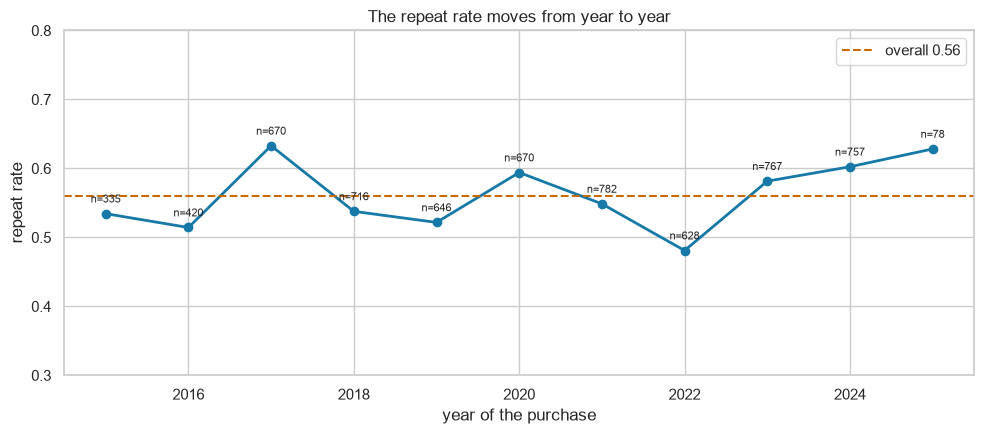

In [32]:
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(by_year.index, by_year["repeat rate"], marker="o", color=PLOT_BLUE, lw=2)
ax.axhline(df[target_col].mean(), color=PLOT_ORANGE, ls="--", label=f"overall {df[target_col].mean():.2f}")
for year, rate, n in zip(by_year.index, by_year["repeat rate"], by_year["rows"]):
    ax.annotate(f"n={n}", (year, rate), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.set(ylim=(0.3, 0.8), xlabel="year of the purchase", ylabel="repeat rate",
       title="The repeat rate moves from year to year")
ax.legend()
plt.tight_layout()
plt.show()

In [33]:
# How much of the recent activity comes from customers we already knew?
recent = train_dates >= "2023-01-01"
past_customers = set(df.loc[~recent, group_col])
returning = df.loc[recent, group_col].isin(past_customers)
print(f"purchases from 2023 onwards: {recent.sum():,}")
print(f"  made by customers who already bought before 2023: {returning.mean():.1%}")
recent_customers = set(df.loc[recent, group_col])
print(f"  customers active in 2023+: {len(recent_customers)} (of which new: {len(recent_customers - past_customers)})")

purchases from 2023 onwards: 1,602
  made by customers who already bought before 2023: 89.5%
  customers active in 2023+: 261 (of which new: 57)


In [34]:
# Cumulative features grow with time by construction. Median by period:
period = pd.cut(train_dates.dt.year, bins=[2014, 2018, 2022, 2025], labels=["2015-2018", "2019-2022", "2023-2025"])
key = ["Total a Pagar", "N_ Detalhes", "days_since_previous_purchase", "purchase_count_90d", "spend_90d",
       "purchase_count_365d", "customer_tenure_days", "prior_purchase_count", "prior_total_spend"]
df.groupby(period, observed=True)[key].median().T.round(1)

purchase_date,2015-2018,2019-2022,2023-2025
Total a Pagar,382.1,489.5,634.4
N_ Detalhes,9.0,12.0,15.0
days_since_previous_purchase,49.0,63.0,61.0
purchase_count_90d,1.0,1.0,1.0
spend_90d,147.9,162.6,352.6
purchase_count_365d,3.0,4.0,4.0
customer_tenure_days,309.0,1238.5,2082.0
prior_purchase_count,4.0,15.0,21.0
prior_total_spend,2275.8,9004.0,15013.7


**What the time structure tells us**

* The repeat rate **moves from year to year** (≈0.48 to ≈0.63), with the most recent years above the average. The
  population the model will meet tomorrow is not exactly the one it learned from: this is *population drift*
  (Data Mining, S3).
* **Most recent purchases come from customers we already know**: 89.5% of the purchases made from 2023 onwards belong
  to customers who had already bought before 2023 (204 of the 261 customers active in that period). Customers come back
  over many years, so a future purchase will usually belong to a customer with a history in the data.
* **Cumulative features grow with time by construction.** Tenure, the number of prior purchases and the total prior
  spend all rise from one period to the next, simply because the company and its customers get older (median tenure
  309 → 1,239 → 2,082 days). Money amounts also rise (invoice median 382 € → 634 €), plausibly inflation and larger
  orders. **Behaviour counts stay stable**: the median recency (≈50–60 days) and the number of purchases in the last 90
  or 365 days barely move.

**Consequences, all following from the business definition of the problem:**

* **Assessment (Part 4):** the validation that imitates real use is **temporal**: train on the past and validate on
  the most recent period, where most customers are already known. A random k-fold mixes future and past, and a
  `GroupKFold` by customer would simulate *new* customers, which is not the usual case. We will compare the designs
  explicitly instead of picking one by assumption.
* **Features:** the purchase *year* will not be used: any future purchase falls in a year the model has never seen.
  Cumulative features will always be extrapolated a little upwards, so behaviour features that do not drift
  (recency, fixed-window frequency, ratios) are the safest candidates.

# <font color='#E8800A'>8 · Univariate analysis</font> <a class="anchor" id="univariate"></a>
[Back to TOC](#toc)

### 8.1 Numeric variables: shape

`.describe()` gives the centre and spread. We add the statistics it leaves out (Week 3): the mean/median ratio, the
skewness and the share of zeros.

From here on we explore **`df_eda`**: the working copy `df` with the row-by-row corrections of Section 6.4 applied
(`apply_row_corrections`). Without them, the 1e9 codes and the inflated values would dominate every statistic, and
rescaling the data would not help: a scaler or a log changes the scale of a column, not the values that are wrong.

In [35]:
# Exploration copy with the row-by-row corrections of Section 6.4 (the same function Part 2 will reuse).
df_eda = apply_row_corrections(df)

shape = df_eda[numeric_cols].describe().T[["mean", "50%", "std", "max"]]
shape["mean/median"] = shape["mean"] / shape["50%"].replace(0, np.nan)
shape["skew"] = df_eda[numeric_cols].skew()
shape["% zeros"] = 100 * (df_eda[numeric_cols] == 0).mean()
shape.sort_values("skew", ascending=False).round(2)

,mean,50%,std,max,mean/median,skew,% zeros
Total Desc_ Global,0.35,0.00,5.12,218.49,NaN,27.46,98.30
prior_max_purchase_value,2946.38,1783.24,5901.55,267526.19,1.65,21.34,0.00
Total Portes,1.15,0.00,5.84,181.06,NaN,19.55,83.72
prior_mean_gap_days,96.18,68.61,122.65,3199.00,1.40,9.31,0.00
prior_std_gap_days,74.14,50.64,101.82,2212.54,1.46,7.77,0.02
days_since_previous_purchase,101.83,57.00,165.84,3199.00,1.79,6.53,0.00
invoice_count_current_purchase,1.07,1.00,0.31,5.00,1.07,6.44,0.00
Total Desc_ Linha,112.47,13.13,289.99,4103.44,8.57,5.92,37.73
prior_min_purchase_value,185.46,64.34,408.40,6298.98,2.88,5.90,0.00
spend_30d,457.14,0.00,1191.23,22297.21,NaN,5.50,67.12


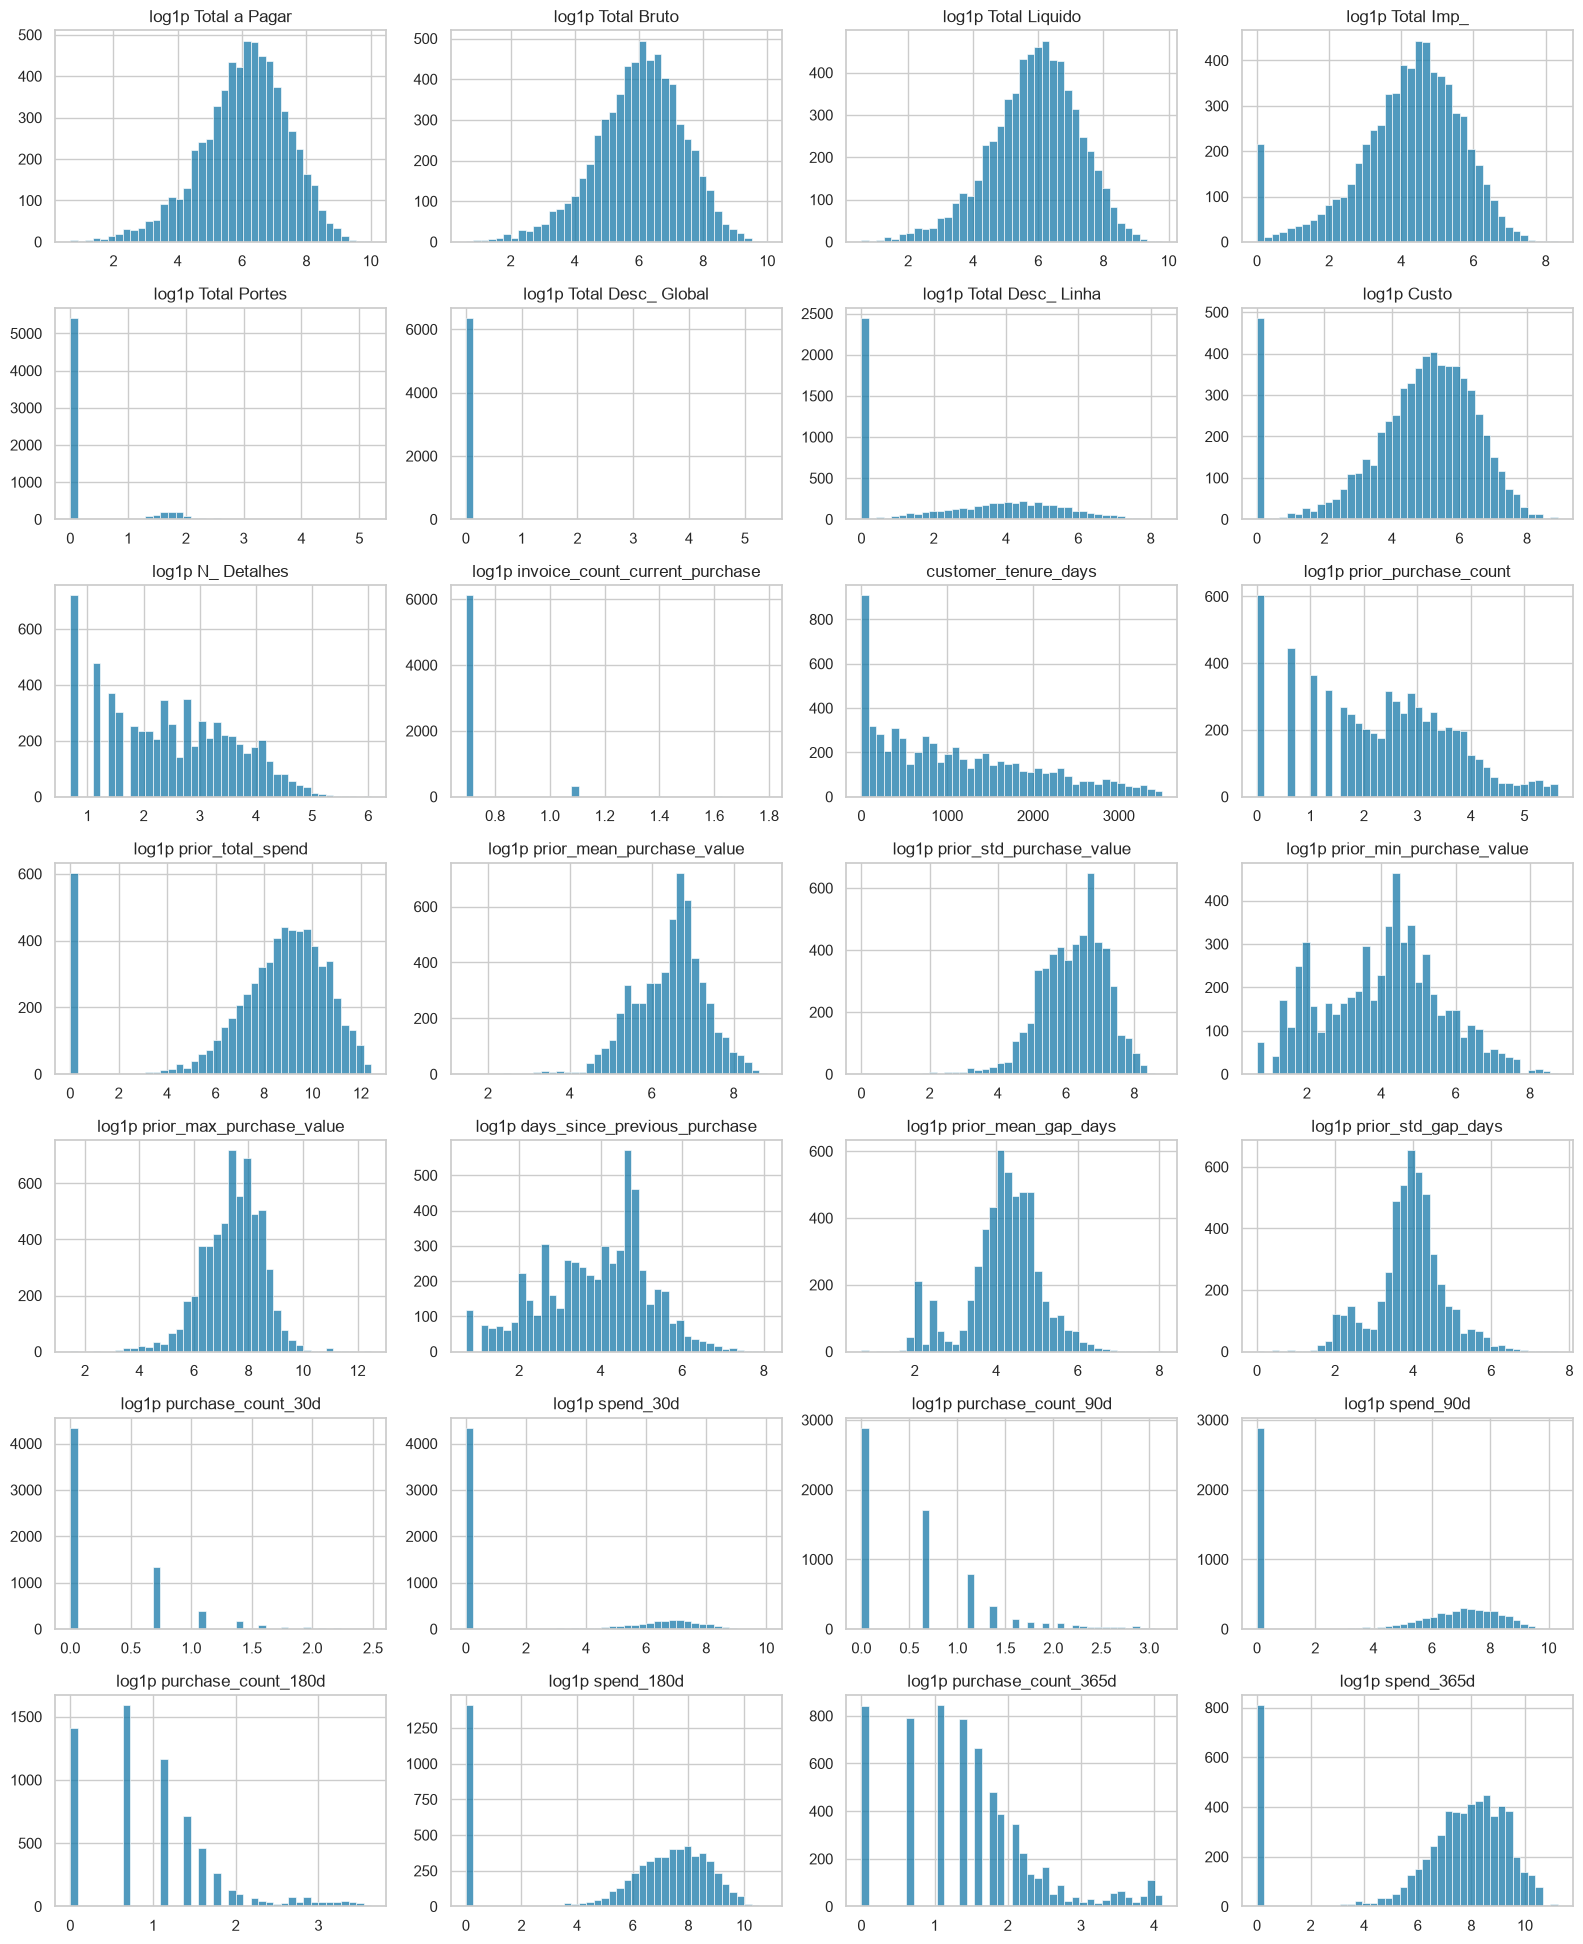

In [36]:
def plot_hist_grid(frame, cols, log_cols=(), n_per_row=4, color=PLOT_BLUE):
    """One histogram per column; columns in `log_cols` are shown as log(1 + x) so long tails are readable."""
    n_rows = int(np.ceil(len(cols) / n_per_row))
    fig, axes = plt.subplots(n_rows, n_per_row, figsize=(4 * n_per_row, 2.8 * n_rows))
    for ax, col in zip(axes.flat, cols):
        values = frame[col].dropna()
        if col in log_cols:
            values = np.log1p(values.clip(lower=0))
        sns.histplot(values, bins=40, color=color, ax=ax)
        ax.set(title=("log1p " if col in log_cols else "") + col, xlabel="", ylabel="")
    for ax in list(axes.flat)[len(cols):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()


skewed = shape.index[shape["skew"] > 2].tolist()
plot_hist_grid(df_eda, numeric_cols, log_cols=skewed)

**What the shapes say**

* Almost every money and count column is **strongly right-skewed** (skew > 2, mean several times the median): many
  small purchases and a long tail of very large ones. On the log scale most of them become roughly bell-shaped, which
  suggests a `log1p` transform for the models that care about scale and linearity (logistic regression).
* `Total Portes` and `Total Desc_ Global` are **zero in the vast majority of rows** (shipping and global discounts
  are rare), so they carry little information; `invoice_count_current_purchase` is almost always 1.
* The rolling-window counts have **many zeros** (most customers did not buy in the last 30 days), which is information,
  not a problem: zero means "no recent purchase".

### 8.2 Where the boxplot rule fails

In [37]:
# The 1.5 x IQR rule on a skewed column: how many rows would it call outliers, and who are they?
rows = []
for col in ["Total a Pagar", "prior_total_spend", "spend_365d", "N_ Detalhes", "prior_purchase_count"]:
    s = df_eda[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    out = s > q3 + 1.5 * (q3 - q1)
    rows.append({"column": col, "% flagged by 1.5 IQR": round(100 * out.mean(), 1),
                 "repeat rate flagged": round(df_eda.loc[out[out].index, target_col].mean(), 3),
                 "repeat rate rest": round(df_eda.loc[out[~out].index, target_col].mean(), 3)})
pd.DataFrame(rows).set_index("column")

,% flagged by 1.5 IQR,repeat rate flagged,repeat rate rest
column,,,
Total a Pagar,9.2,0.674,0.548
prior_total_spend,9.9,0.841,0.529
spend_365d,7.0,0.885,0.535
N_ Detalhes,6.7,0.635,0.554
prior_purchase_count,7.7,0.974,0.525


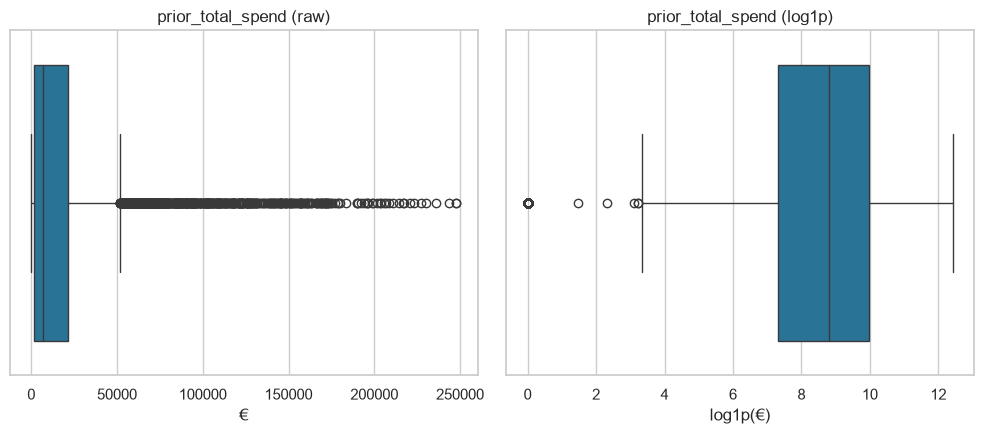

In [38]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE)
sns.boxplot(x=df_eda["prior_total_spend"], color=PLOT_BLUE, ax=axes[0])
axes[0].set(title="prior_total_spend (raw)", xlabel="€")
sns.boxplot(x=np.log1p(df_eda["prior_total_spend"]), color=PLOT_BLUE, ax=axes[1])
axes[1].set(title="prior_total_spend (log1p)", xlabel="log1p(€)")
plt.tight_layout()
plt.show()

* On skewed columns the 1.5 × IQR rule flags **7–10% of the rows** as "outliers".
* These are not errors: they are the **best customers**. Their repeat rate is far higher than the rest: 0.97 vs 0.53
  for `prior_purchase_count`, 0.88 vs 0.54 for `spend_365d`. Deleting
  them would remove exactly the customers the company most wants to keep and would bias the class balance (the same
  lesson as Week 3, where the IQR drop removed 67% of the data).
* On the log scale the boxplot becomes symmetric and the "outliers" mostly disappear.
* → **Planned fix:** keep every row with a legitimate value; compress the tails with `log1p` instead of cutting them.
  The only values removed are the impossible ones from 6.4.

### 8.3 Categorical variables

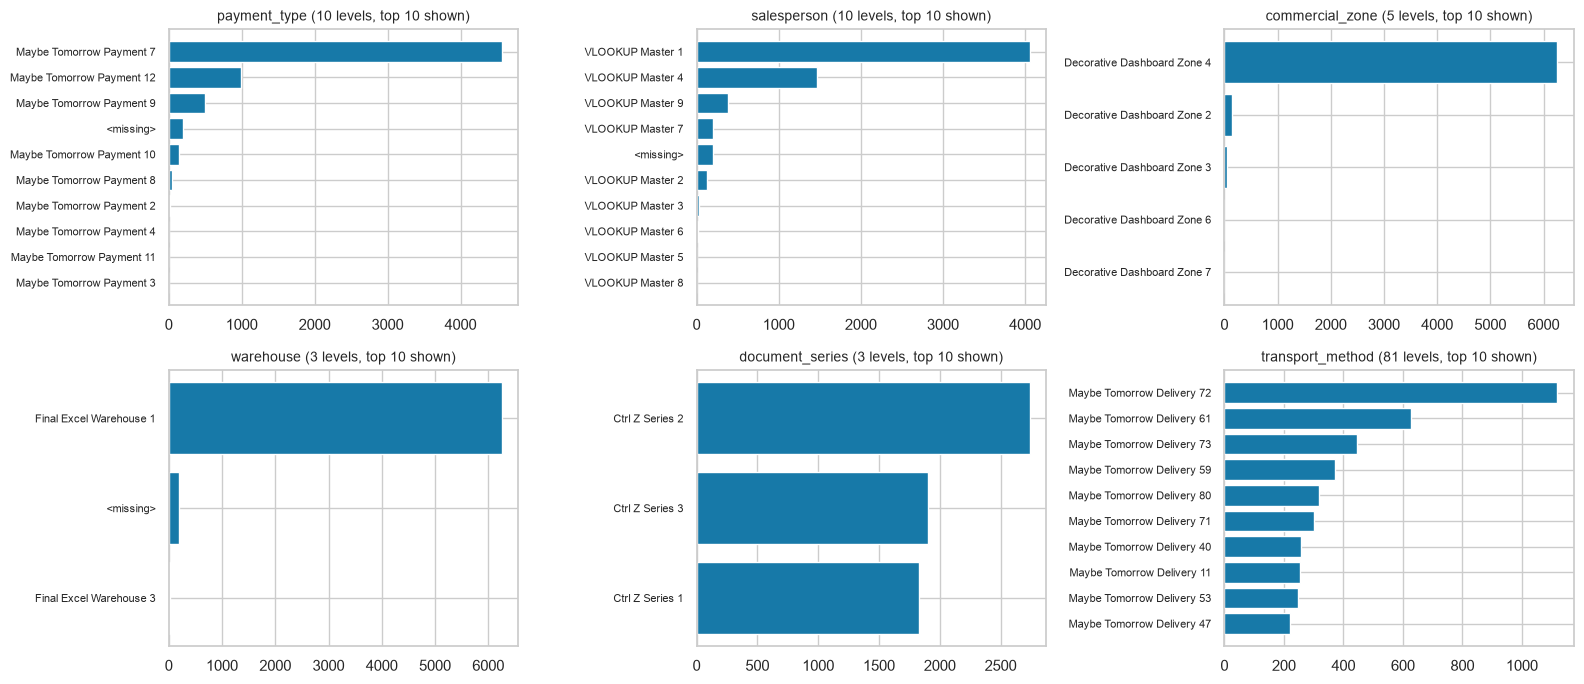

In [39]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col in zip(axes.flat, categorical_cols):
    counts = df_eda[col].fillna("<missing>").value_counts()
    top = counts.head(10)
    ax.barh(top.index[::-1], top.values[::-1], color=PLOT_BLUE)
    ax.set_title(f"{col} ({counts.size} levels, top 10 shown)", fontsize=10)
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

* `warehouse` (99.7%) and `commercial_zone` (97%) are almost constant; `salesperson` has one main level (65%);
  `document_series` is split across three series.
* `transport_method` has a long tail: a handful of methods cover most rows, and dozens appear only a few times.
* `payment_type` is more spread out, with several frequent levels.

# <font color='#E8800A'>9 · Relationships with the target</font> <a class="anchor" id="bivariate"></a>
[Back to TOC](#toc)

### 9.1 Which numeric variables separate repeaters from non-repeaters?

For a numeric variable against a binary target, the course measure is the **point-biserial correlation** (Pearson's r
with a 0/1 variable). Because the variables are skewed, we compute it on `log1p` values, and we also report the
**Spearman** correlation, which uses ranks and is robust to the tails. We also show the **median** in each class.

In [40]:
def signed_log1p(s):
    return np.sign(s) * np.log1p(np.abs(s))


rel_rows = []
for col in numeric_cols:
    pair = df_eda[[col, target_col]].dropna()
    r_pb, p_pb = stats.pointbiserialr(pair[target_col], signed_log1p(pair[col]))
    rho, _ = stats.spearmanr(pair[col], pair[target_col])
    rel_rows.append({"feature": col, "point-biserial r (log1p)": r_pb, "Spearman rho": rho, "p-value": p_pb,
                     "median | 0": pair.loc[pair[target_col] == 0, col].median(),
                     "median | 1": pair.loc[pair[target_col] == 1, col].median()})
relevance = pd.DataFrame(rel_rows).set_index("feature")
relevance = relevance.reindex(relevance["Spearman rho"].abs().sort_values(ascending=False).index)
relevance.round(3)

,point-biserial r (log1p),Spearman rho,p-value,median | 0,median | 1
feature,,,,,
purchase_count_365d,0.424,0.437,0.000,2.000,5.000
prior_mean_gap_days,-0.389,-0.420,0.000,101.750,55.758
purchase_count_180d,0.407,0.406,0.000,1.000,3.000
purchase_count_90d,0.396,0.393,0.000,0.000,1.000
spend_365d,0.310,0.391,0.000,1128.650,4480.910
spend_180d,0.317,0.370,0.000,457.870,2106.220
spend_90d,0.351,0.359,0.000,0.000,746.190
prior_purchase_count,0.346,0.346,0.000,6.000,17.000
prior_total_spend,0.275,0.332,0.000,3246.525,12098.990


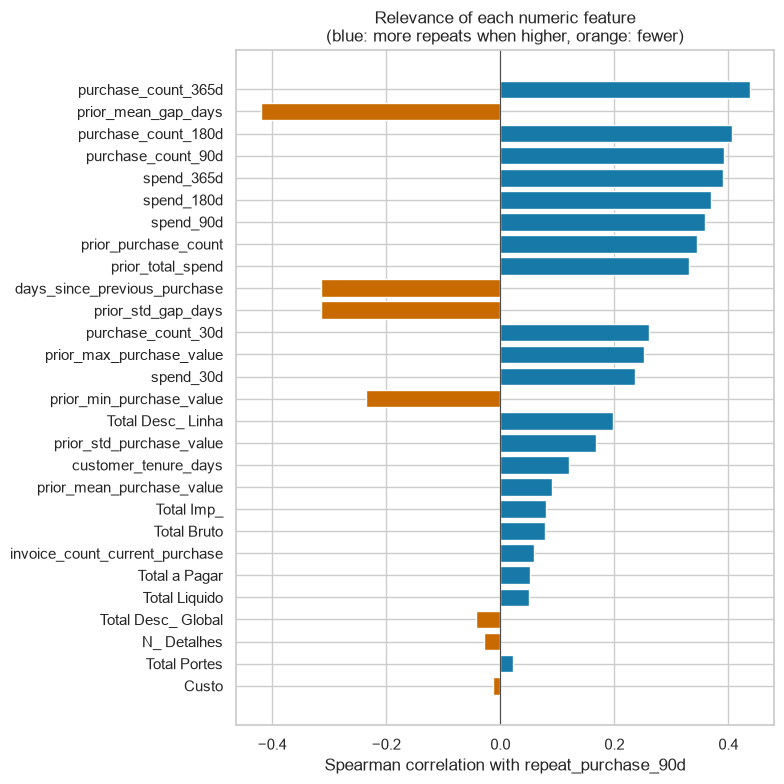

In [41]:
fig, ax = plt.subplots(figsize=(8, 8))
values = relevance["Spearman rho"]
ax.barh(values.index[::-1], values.values[::-1],
        color=[PLOT_BLUE if v > 0 else PLOT_ORANGE for v in values.values[::-1]])
ax.axvline(0, color="0.3", lw=0.8)
ax.set(xlabel="Spearman correlation with repeat_purchase_90d",
       title="Relevance of each numeric feature\n(blue: more repeats when higher, orange: fewer)")
plt.tight_layout()
plt.show()

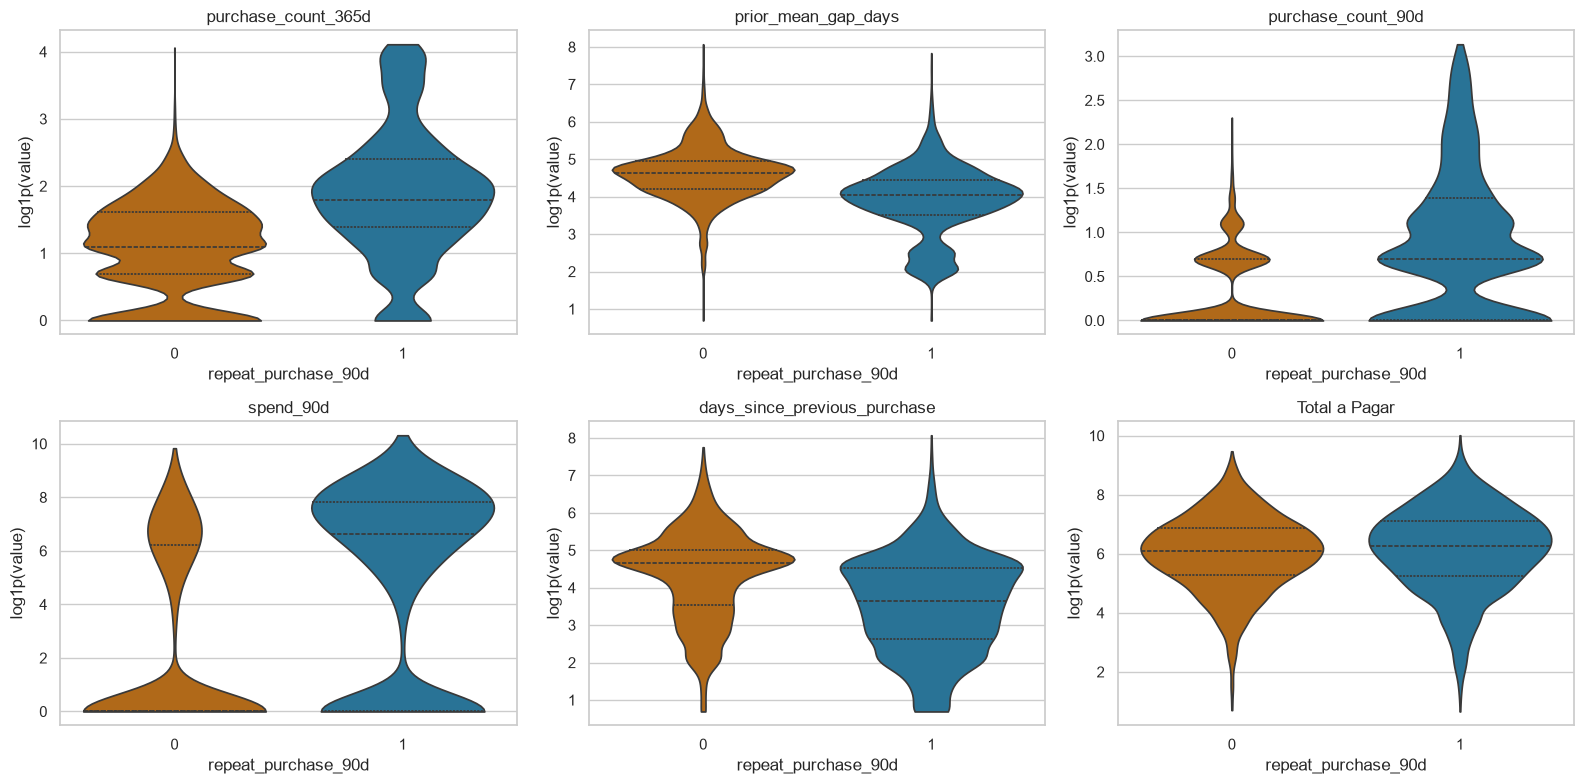

In [42]:
# The same question seen as distributions: each strong feature split by the target (log scale for the tails).
top_features = ["purchase_count_365d", "prior_mean_gap_days", "purchase_count_90d", "spend_90d",
                "days_since_previous_purchase", "Total a Pagar"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, top_features):
    plot_data = pd.DataFrame({"value": np.log1p(df_eda[col].clip(lower=0)), target_col: df_eda[target_col]}).dropna()
    sns.violinplot(data=plot_data, x=target_col, y="value", hue=target_col, palette=[PLOT_ORANGE, PLOT_BLUE],
                   inner="quartile", cut=0, legend=False, ax=ax)
    ax.set(title=col, xlabel="repeat_purchase_90d", ylabel="log1p(value)")
plt.tight_layout()
plt.show()

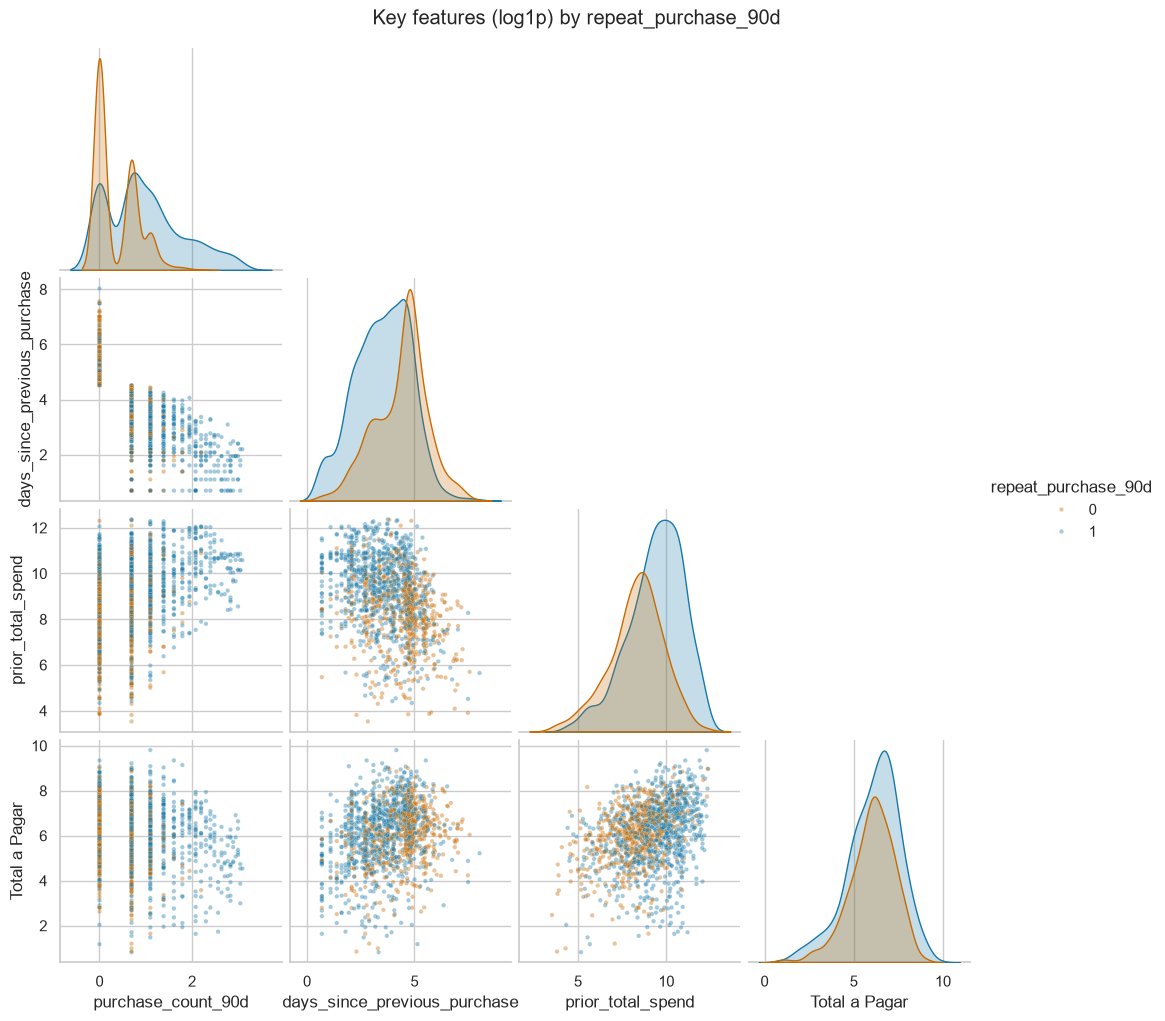

In [43]:
# Pairplot of four key features (log scale), coloured by the target, on a fixed random sample for readability.
pair_cols = ["purchase_count_90d", "days_since_previous_purchase", "prior_total_spend", "Total a Pagar"]
sample = df_eda[pair_cols + [target_col]].dropna().sample(1500, random_state=RANDOM_STATE)
sample[pair_cols] = np.log1p(sample[pair_cols].clip(lower=0))
grid = sns.pairplot(sample, hue=target_col, palette=[PLOT_ORANGE, PLOT_BLUE], corner=True,
                    plot_kws={"s": 10, "alpha": 0.4}, diag_kind="kde")
grid.figure.suptitle("Key features (log1p) by repeat_purchase_90d", y=1.02)
plt.show()

**Reading the distributions**

* The violins confirm the ranking: repeaters have clearly **more** purchases in the last 90 and 365 days and **shorter**
  gaps, while the amount of the current invoice (`Total a Pagar`) has almost identical shapes in both classes.
* The pairplot shows that **no single feature separates the classes**: the clouds overlap everywhere. The model has to
  combine several weak signals, which is also why the F1 floor is hard to beat by a wide margin.
* It also shows a link **built into the data**: every row with `purchase_count_90d = 0` has
  `days_since_previous_purchase` above ≈90 days (log1p ≈ 4.5). By definition, no purchase in the last 90 days means the
  previous purchase is older than 90 days. The two columns partly carry the same information, a point for the
  redundancy analysis in Section 10.

**Reading the ranking**

* **Recency and recent frequency dominate.** The strongest signals are the rolling-window counts and spends
  (`purchase_count_90d`, `purchase_count_180d`, `spend_90d`, ...), positively, and `days_since_previous_purchase` and
  `prior_mean_gap_days`, negatively. Customers who buy *often* and *recently* come back: the classic RFM logic
  (Recency, Frequency, Monetary).
* **The size of the current invoice matters much less** than the customer's rhythm. The invoice amounts have small
  correlations.
* `customer_tenure_days` is weakly related: being an old customer is not the same as being an active one.
* With n ≈ 6,500, even tiny correlations have small p-values. Statistical significance is not the same as usefulness
  (Data Mining, S3), so we read the **effect size**, not the p-value.

### 9.2 The recency effect in detail

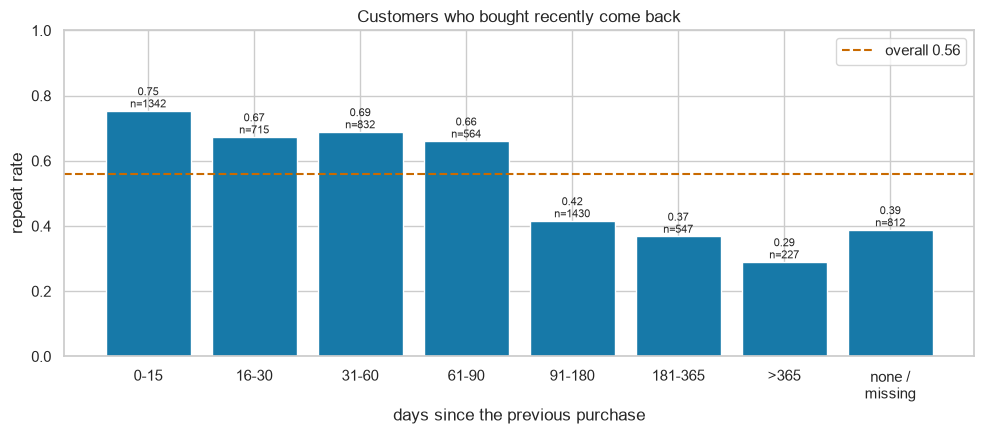

In [44]:
bins = [0, 15, 30, 60, 90, 180, 365, np.inf]
labels = ["0-15", "16-30", "31-60", "61-90", "91-180", "181-365", ">365"]
recency = pd.cut(df_eda["days_since_previous_purchase"], bins=bins, labels=labels, include_lowest=True)
recency = recency.cat.add_categories("none /\nmissing").fillna("none /\nmissing")
by_recency = df_eda.groupby(recency, observed=True)[target_col].agg(["mean", "size"]).rename(
    columns={"mean": "repeat rate", "size": "rows"})

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.bar(by_recency.index.astype(str), by_recency["repeat rate"], color=PLOT_BLUE)
ax.axhline(df_eda[target_col].mean(), color=PLOT_ORANGE, ls="--", label=f"overall {df_eda[target_col].mean():.2f}")
for i, (rate, n) in enumerate(zip(by_recency["repeat rate"], by_recency["rows"])):
    ax.text(i, rate + 0.01, f"{rate:.2f}\nn={n}", ha="center", fontsize=8)
ax.set(ylim=(0, 1), xlabel="days since the previous purchase", ylabel="repeat rate",
       title="Customers who bought recently come back")
ax.legend()
plt.tight_layout()
plt.show()

In [45]:
# Frequency: repeat rate by number of purchases in the previous 90 days.
freq = df_eda["purchase_count_90d"].clip(upper=6).astype("Int64").astype(str).replace({"6": "6+"})
df_eda.groupby(freq)[target_col].agg(["mean", "size"]).rename(columns={"mean": "repeat rate", "size": "rows"}).round(3)

,repeat rate,rows
purchase_count_90d,,
0,0.379,2889
1,0.568,1714
2,0.712,787
3,0.832,328
4,0.879,149
5,0.940,100
6+,0.986,502


In [57]:
first_purchase = df_eda["prior_purchase_count"] == 0
print(f"first purchases: {first_purchase.sum()} rows, repeat rate {df_eda.loc[first_purchase, target_col].mean():.3f}")

first purchases: 603 rows, repeat rate 0.333


* There is a **clear break around 90 days**: customers whose previous purchase was less than 90 days ago come back in
  ≈66–75% of the cases; beyond 90 days the rate falls to ≈40%, and to ≈30% after a year. The relationship is
  monotonic but **not linear**, which supports binning or a `log1p` transform for a linear model.
* **First-time buyers** (no previous purchase) come back in only **33%** of the cases, the lowest rate of all groups.
  This is another reason to keep an explicit `is_first_purchase` flag rather than filling their gaps with a number.
* Frequency tells the same story even more sharply: with no purchase in the previous 90 days the rate is 38%, with one
  57%, with three 83%, and with six or more 99%.

**Feature engineering idea for Part 2:** the absolute recency means different things for different customers (30 days
is long for a weekly buyer and short for a yearly buyer). A ratio such as
`days_since_previous_purchase / prior_mean_gap_days` ("is the customer early or late compared with their own rhythm?")
puts every customer on the same scale.

In [47]:
# Quick check of that idea (exploration only): repeat rate by quintile of the rhythm ratio.
rhythm = df_eda["days_since_previous_purchase"] / df_eda["prior_mean_gap_days"].replace(0, np.nan)
df_eda.groupby(pd.qcut(rhythm, 5), observed=True)[target_col].agg(["mean", "size"]).rename(
    columns={"mean": "repeat rate", "size": "rows"}).round(3)

,repeat rate,rows
"(0.00017, 0.257]",0.595,1007
"(0.257, 0.626]",0.683,1006
"(0.626, 1.045]",0.594,1006
"(1.045, 1.747]",0.570,1006
"(1.747, 478.667]",0.553,1006


The ratio has signal, but it is not monotonic: customers who are at about half of their usual gap come back most,
while customers who are far beyond their usual gap come back least. It is a candidate feature that feature
selection will have to judge, not a guaranteed winner.

### 9.3 Categorical variables vs the target

For two categorical variables the course measure is the **chi-square test** with **Cramér's V** as the effect size.
Rare levels make the chi-square approximation unreliable (expected counts < 5), so we report the smallest expected count too.

In [48]:
cat_rows = []
for col in categorical_cols:
    x = df_eda[col].fillna("<missing>")
    table = pd.crosstab(x, df_eda[target_col])
    chi2, p_value, _, expected = chi2_contingency(table, correction=False)
    v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
    cat_rows.append({"feature": col, "levels": table.shape[0], "chi2": chi2, "p-value": p_value,
                     "Cramer's V": v, "min expected count": expected.min()})
pd.DataFrame(cat_rows).set_index("feature").sort_values("Cramer's V", ascending=False).round(4)

,levels,chi2,p-value,Cramer's V,min expected count
feature,,,,,
transport_method,81,527.2252,0.0000,0.2855,0.4403
payment_type,10,354.3527,0.0000,0.2340,1.7610
salesperson,10,260.7604,0.0000,0.2008,1.3208
commercial_zone,5,26.2955,0.0000,0.0638,0.4403
warehouse,3,10.1673,0.0062,0.0396,9.2453
document_series,3,0.0553,0.9727,0.0029,804.7834


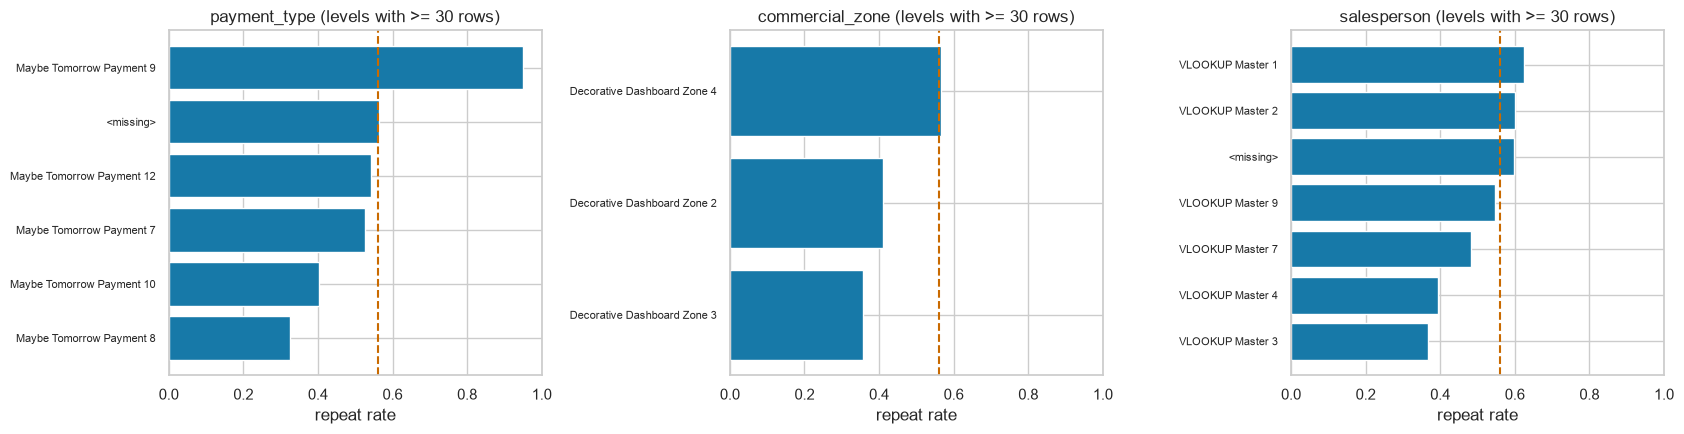

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["payment_type", "commercial_zone", "salesperson"]):
    stats_by_level = df_eda.groupby(df_eda[col].fillna("<missing>"))[target_col].agg(["mean", "size"])
    stats_by_level = stats_by_level[stats_by_level["size"] >= 30].sort_values("mean")
    ax.barh(stats_by_level.index, stats_by_level["mean"], color=PLOT_BLUE)
    ax.axvline(df_eda[target_col].mean(), color=PLOT_ORANGE, ls="--")
    ax.set(xlim=(0, 1), title=f"{col} (levels with >= 30 rows)", xlabel="repeat rate")
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

* `transport_method`, `payment_type` and `salesperson` show a moderate association (Cramér's V 0.20–0.29). Some payment types
  have repeat rates far above or below the average, which is plausible: payment terms reflect the type of commercial
  relationship (regular account customers vs one-off buyers).
* `transport_method` has a high V partly *because* it has 80 levels: many tiny levels with extreme rates inflate the
  statistic (and their expected counts are far below 5). Grouping rare levels into `"Other"` is what makes this
  variable usable without overfitting.
* `commercial_zone` and `warehouse` are weakly related, and `document_series` is unrelated (V ≈ 0, p = 0.97).

# <font color='#E8800A'>10 · Redundancy between predictors</font> <a class="anchor" id="redundancy"></a>
[Back to TOC](#toc)

A relevance ranking compares each column with the target only. Two columns can both be relevant and still say the
same thing. We use the **Spearman** correlation (robust to the skewed tails) between all numeric columns, and list
the pairs above 0.90.

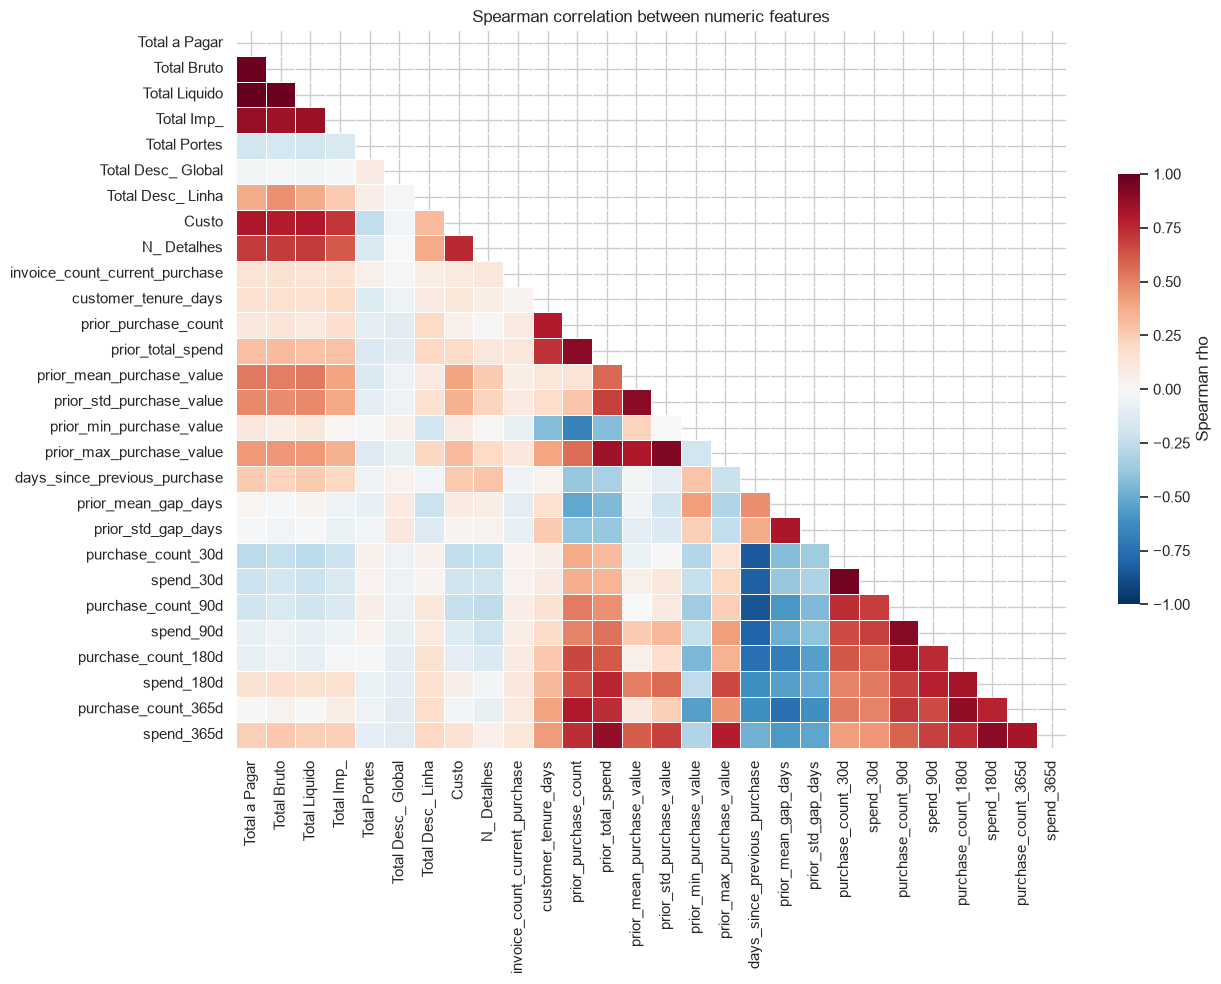

In [50]:
corr = df_eda[numeric_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0, linewidths=0.5,
            cbar_kws={"shrink": 0.6, "label": "Spearman rho"}, ax=ax)
ax.set_title("Spearman correlation between numeric features")
plt.tight_layout()
plt.show()

In [51]:
pairs = (corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1)).stack()
         .rename("Spearman rho").reset_index().rename(columns={"level_0": "feature A", "level_1": "feature B"}))
pairs = pairs.reindex(pairs["Spearman rho"].abs().sort_values(ascending=False).index)
pairs[pairs["Spearman rho"].abs() >= 0.90].round(3).reset_index(drop=True)

,feature A,feature B,Spearman rho
0,Total Liquido,Total a Pagar,1.000
1,Total Liquido,Total Bruto,0.991
2,Total Bruto,Total a Pagar,0.991
3,spend_30d,purchase_count_30d,0.965
4,prior_max_purchase_value,prior_std_purchase_value,0.923
5,spend_90d,purchase_count_90d,0.909
6,prior_total_spend,prior_purchase_count,0.903
7,spend_365d,spend_180d,0.901


Eight pairs exceed 0.90:

* `Total a Pagar`, `Total Bruto` and `Total Liquido` (ρ 0.99–1.00). Section 6.5 showed why: they are linked by
  accounting identities. One of them carries all the information.
* Short-window counts and spends: `purchase_count_30d` ↔ `spend_30d` (0.97), `purchase_count_90d` ↔ `spend_90d` (0.91).
* `prior_purchase_count` ↔ `prior_total_spend` (0.90) and `prior_max_purchase_value` ↔ `prior_std_purchase_value` (0.92).
* `spend_365d` ↔ `spend_180d` (0.90): once the inflated 365-day values are removed (Section 6.4), the two windows are
  almost the same variable.
* `prior_mean_purchase_value` is not in the list, yet it is the most redundant column of all: Section 6.4 showed it is
  *exactly* `prior_total_spend / prior_purchase_count`. A ratio of two columns is not linearly related to either of them,
  so a correlation matrix cannot see this kind of redundancy. Knowing how a column is built matters as much as
  measuring it.
* Below the 0.90 line the heatmap still shows large blocks (the nested windows among themselves, the invoice amounts
  with `Total Imp_` and `Custo`), so the redundancy is broader than these eight pairs.
* Redundancy hurts a **linear** model the most (unstable coefficients under multicollinearity). → **Planned for Part 3:**
  a redundancy filter (|ρ| > 0.90: keep the more relevant of each pair), followed by the wrapper and embedded methods.

# <font color='#E8800A'>11 · The customer table `clientes.csv`</font> <a class="anchor" id="clientes"></a>
[Back to TOC](#toc)

The brief asks us to *decide whether and how* to integrate this table through `customer_id`. We first check its quality,
then whether it adds anything that is not already in the transactions.

In [52]:
# The key: unique in clientes, and does every training customer have a record?
print(f"{len(df_clientes):,} customers in clientes.csv, customer_id unique: {df_clientes[group_col].is_unique}")
print(f"training customers found in clientes: {df[group_col].isin(df_clientes[group_col]).mean():.0%}")

# Quality is measured on OUR customers only: the other rows of the table never reach the model.
clientes_train = df_clientes[df_clientes[group_col].isin(df[group_col])]
quality = pd.DataFrame({
    "% missing": (100 * clientes_train.isna().mean()).round(1),
    "distinct values": clientes_train.nunique(),
    "distinct / customers": (clientes_train.nunique() / len(clientes_train)).round(3),
})
print(f"training customers described: {len(clientes_train)}")
quality

1,143 customers in clientes.csv, customer_id unique: True
training customers found in clientes: 100%
training customers described: 607


,% missing,distinct values,distinct / customers
customer_id,0.0,607,1.000
country_or_region,0.0,7,0.012
commercial_region,2.0,32,0.053
island,46.8,10,0.016
municipality,6.8,150,0.247
city,38.6,259,0.427
postal_area,6.6,188,0.310
postal_code,3.3,516,0.850
street,54.2,264,0.435
address,0.0,597,0.984


* `customer_id` is a clean key: unique in `clientes.csv`, and **every** training customer is found. The table also
  holds 1,143 customers against 610 in train. The extra customers are harmless as long as (1) the join is a
  **left join from the purchases** (each purchase fetches its customer; customers without purchases are simply not
  used, and the number of rows does not change) and (2) **no statistic is computed on the whole table**: the quality
  check above, and any frequency or imputation value in Part 2, uses only the rows of our training customers.
* `customer_type` is **100% empty** → useless.
* `company_name`, `address`, `street`, `postal_code`, `city` are (almost) unique per customer: they identify the customer
  rather than describe them, with the same risk as using `customer_id` itself (memorising customers). Several are
  also half empty.
* 607 of the 610 training customers are described here: the other 3 only appear in the 65 empty rows dropped in 6.1.
* The usable candidates are the coarse geography (among our customers: `country_or_region` 7 levels,
  `commercial_region` 32, `island` 10, `municipality` 150) and `customer_since_year`.

In [53]:
# Attach the candidate columns to each purchase, then measure their association with the target.
candidates = ["country_or_region", "commercial_region", "island", "municipality", "customer_since_year"]
joined = df_eda.join(df_clientes.set_index(group_col)[candidates], on=group_col)

rows = []
for col in candidates:
    x = joined[col].astype("string").fillna("<missing>")
    table = pd.crosstab(x, joined[target_col])
    chi2, p_value, _, expected = chi2_contingency(table, correction=False)
    rows.append({"feature": col, "levels": table.shape[0],
                 "Cramer's V": np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1))),
                 "min expected count": expected.min()})
pd.DataFrame(rows).set_index("feature").round(3)

,levels,Cramer's V,min expected count
feature,,,
country_or_region,7,0.066,0.440
commercial_region,33,0.264,0.440
island,11,0.148,4.403
municipality,151,0.365,0.440
customer_since_year,10,0.196,11.447


In [54]:
# Is customer_since_year new information, or the same as customer_tenure_days?
purchase_year = pd.to_datetime(joined["purchase_date"]).dt.year
years_as_customer = purchase_year - joined["customer_since_year"]
rho, _ = stats.spearmanr(years_as_customer, joined["customer_tenure_days"], nan_policy="omit")
print(f"Spearman(purchase year - customer_since_year, customer_tenure_days) = {rho:.3f}")
print(f"purchases made BEFORE the customer_since_year: {(years_as_customer < 0).mean():.1%}")

Spearman(purchase year - customer_since_year, customer_tenure_days) = 0.917
purchases made BEFORE the customer_since_year: 0.0%


**Decision on `clientes.csv` (to be implemented in Part 2)**

* **Integrate, but only the coarse geography**: `country_or_region`, `commercial_region` and `island` (missing →
  `"Missing"`, rare levels → `"Other"`). They are clean descriptions of *where* the customer is, which could matter for
  logistics and sales coverage. Their association with the target ranges from weak (`country_or_region`, V = 0.07) to
  moderate (`commercial_region`, V = 0.26). Part of the latter comes from its 33 levels, many of them tiny, the same
  inflation we saw with `transport_method`. The feature selection judges them like every other feature: if they add
  nothing, they are dropped there, and the PDF will say so.
* **Do not use** `customer_type` (empty), `company_name`, `address`, `street`, `postal_code`, `city` (identifiers in
  disguise) or `municipality` (150 levels for 607 customers: too fine to generalise; its high V = 0.37 is mostly memorisation of
  the few customers in each municipality).
* **Do not use** `customer_since_year`: "years since the customer joined" correlates at ρ = 0.92 with
  `customer_tenure_days`, which is measured to the day and already in the transactions. The two tables are
  consistent (no purchase happens before the customer's joining year), so the year adds nothing new.

High-cardinality geography deserves the same suspicion as identifiers: with only 610 customers, a municipality with
two customers is essentially a customer ID.

# <font color='#E8800A'>12 · Identifiers and the noise column</font> <a class="anchor" id="identifiers"></a>
[Back to TOC](#toc)

The brief asks to treat identifier-like variables *critically rather than accepting them automatically*. We test
`ID`, `customer_id` and `random_noise` against the target and against the time.

In [55]:
id_frame = df.reset_index()
checks = pd.DataFrame({
    "Spearman with target": [stats.spearmanr(id_frame[c], id_frame[target_col])[0]
                             for c in ["ID", group_col, "random_noise"]],
    "Spearman with purchase date": [stats.spearmanr(id_frame[c], pd.to_datetime(id_frame["purchase_date"]).astype("int64"))[0]
                                    for c in ["ID", group_col, "random_noise"]],
}, index=["ID", group_col, "random_noise"])
checks.round(3)

,Spearman with target,Spearman with purchase date
ID,0.012,0.011
customer_id,-0.116,-0.022
random_noise,-0.008,0.018


In [56]:
# Why would customer_id correlate with the target at all? Look at the customers with the most rows.
top = per_customer.sort_values(ascending=False).head(5)
summary = df[df[group_col].isin(top.index)].groupby(group_col)[target_col].agg(["size", "mean"])
summary.rename(columns={"size": "purchases", "mean": "repeat rate"}).sort_values("purchases", ascending=False).round(3)

,purchases,repeat rate
customer_id,,
103940,276,0.993
258332,200,1.000
755628,107,0.944
151492,88,0.852
519184,88,0.875


* **`ID`** is a row number: no relation with the target or with time. It stays as the index (needed for the
  submission) and is never a feature.
* **`customer_id`** shows a small correlation with the target (ρ ≈ −0.1). That is a **spurious relationship**: the
  number is an arbitrary code, and the correlation appears only because a few very active customers (hundreds of
  purchases, repeat rates close to 1) happen to have particular ID values. A model could "learn" that numeric range
  and memorise those customers, which says nothing about a new purchase pattern. It is excluded as a feature
  (Data Mining, S3: features should have a *meaningful and defensible* relationship with the phenomenon). It is still
  useful as a **key** for the join with `clientes.csv` and for any customer-aware validation check.
* **`random_noise`** has no relation with anything (ρ ≈ 0 with the target and with time). Its name says what it is.
  We will **not** delete it by hand: we keep it as a *control* in feature selection (Part 3). A sound selection
  strategy should discard it on its own, and if a method keeps it, that method is overfitting.

# <font color='#E8800A'>13 · Key findings and decisions carried to Part 2</font> <a class="anchor" id="findings"></a>
[Back to TOC](#toc)

**What we learned**

1. **The target is 56% positive and the metric is F1 of class 1**, so "everybody repeats" already scores F1 ≈ 0.72.
   Every result must beat that floor, and the classification threshold must be tuned.
2. **The data is mostly clean but has deliberate traps**: 65 empty rows; impossible values (1e9 codes, −4 days, sign
   errors) and values that look normal but contradict their own row (46 inflated means, 39 inflated 365-day spends);
   structural missingness in the history columns; many rare categorical levels; and a `random_noise` column.
   **Many of the wrong values can be recovered exactly** (`prior_mean_purchase_value` = total / count, sign corrections),
   which is better than imputing them.
3. **The model always predicts the future.** The repeat rate drifts between years, recent purchases come mostly from
   known customers, and cumulative features (tenure, total history) grow with time. The purchase year cannot be used,
   and the validation must be temporal.
4. **Behaviour beats size**: recency and frequency (RFM) are by far the strongest signals; invoice amounts are weak.
   There is a sharp break in the repeat rate at ≈90 days since the previous purchase.
5. **Strong redundancy**: the three invoice totals, short-window count/spend pairs, `spend_365d`/`spend_180d` and two
   history pairs are near-duplicates (ρ > 0.9), and `prior_mean_purchase_value` is an exact ratio of two other columns.
6. **Outliers are customers, not errors**: the IQR rule would flag 7–10% of the rows, mostly loyal high-value customers
   whose repeat rate is 84–97%.
7. **`clientes.csv`** is clean as a key; only its coarse geography is worth testing.

**Decisions carried to Part 2 (pre-processing) and beyond**

| Step | Decision | Fitted on |
|---|---|---|
| Rows | drop the 65 empty rows from training | rule |
| Impossible values | `apply_row_corrections`: recompute the mean as total / count, fix sign errors, unrecoverable values (1e9, −4, out of bounds) → `NaN` | rule (row by row) |
| Missing history | `is_first_purchase` flag + missing indicators + median imputation | training rows |
| Missing categories | `"Missing"` level | rule |
| Rare / unseen levels | grouped into `"Other"` via `min_frequency` / `handle_unknown` | training rows |
| Long tails | `log1p` on money, count and gap columns; no outlier deletion | rule |
| Scaling | `StandardScaler` for the linear model | training rows |
| `clientes.csv` | join `country_or_region`, `commercial_region`, `island` | — |
| New features | recency/rhythm ratio, margin and discount ratios, spend acceleration; **no** purchase year | rule |
| Identifiers | `ID` = index; `customer_id` = join key only; `random_noise` kept as a selection control | — |
| Validation (Part 4) | temporal hold-out as the main design, compared with stratified and grouped k-fold | — |
| Metric (Part 4) | F1 of class 1 vs the all-ones floor, with threshold tuning; precision, recall and AUC as support | — |